# MorphoNup — modality analysis

Which inputs matter? Input set: sequence only (no shape anywhere), shape only (no sequence routes), shuffled shape (MorphoNup unchanged, but every sequence gets another sequence's shape tracks). Shape preprocessing: without the PLS reduction (same 10 tracks), all 14 tracks unreduced (no preprocessing at all), and without EP. All arms are retrained with the same splits, seeds and recipe and compared with MorphoNup on the same outer test rows.

Key contrasts: MorphoNup − sequence only = value of shape; − shape only = value of sequence; − shuffled shape = value of the shape information beyond its extra parameters (shape is computed from the sequence); − no PLS = value of the reduction; − all 14 tracks = value of the whole shape preprocessing; − no EP = value of EP.

Statistics, figures and tables as in the architecture analysis (forest plot `deltas`, box plot `boxplot_accuracy`, heatmap, metric panel, discordance, ROC/PR, training curves; `manuscript_table`, `metrics_table`), plus `roc_pr_arms` (ROC and precision–recall curves of MorphoNup and the three input-set variants in one panel).

`RUN_MODE = "background"` trains the missing arms one after another in a single detached job (MorphoNup itself must already be trained for this dataset and k, with the same seeds). Figures and tables are refreshed automatically whenever an arm finishes a seed; the Results cells display them.

In [1]:
DATASET = "DatasetNup_1/Homo_sapiens"
K_FOLDS = 5
SEEDS = [151000, 152000, 153000]          # the reported seeds (config.SEEDS)
GROUP = "modality"
ARMS = None                               # None = every arm of the group; or a list such as ["no_kmer"]
RUN_MODE = "results_only"                # "background" | "inline" | "results_only"
CHAINS = 2                                # parallel jobs; each trains its share of the arms one after another
ALLOW_BUSY_GPU = False

In [2]:
import os
import sys
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
_null, _err = os.open(os.devnull, os.O_WRONLY), os.dup(2)
os.dup2(_null, 2)                                    # TensorFlow's CUDA start-up lines go to C-level stderr
try:
    import tensorflow  # noqa: F401
finally:
    os.dup2(_err, 2)
    os.close(_null)
    os.close(_err)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "morphonup" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display

from morphonup import config, figures, jobs
from morphonup.cv import run_dir

pd.set_option("display.width", 200, "display.max_columns", 40)


def show(path, width=900):
    """Display a saved figure with its caption (from the folder's figure_catalog.csv)."""
    path = Path(path)
    if not path.exists():
        print("missing:", path.relative_to(ROOT))
        return
    cat = path.parent / "figure_catalog.csv"
    caption = pd.read_csv(cat).set_index("png").suggested_caption.get(path.name, "") if cat.exists() else ""
    display(Markdown(f"**{path.stem}** — `{path.relative_to(ROOT)}`  \n{caption}"))
    display(Image(filename=str(path), width=width))
from morphonup import analysis, arms

ARM_LIST = ARMS or arms.GROUPS[GROUP]
TRAIN = [a for a in ARM_LIST if a in arms.ARMS]
K_DIR = run_dir(DATASET, K_FOLDS).parent
display(arms.table().set_index("arm").loc[ARM_LIST, ["label", "change", "needs_training"]])
full = jobs.progress(DATASET, K_FOLDS, SEEDS)
print("MorphoNup seeds finished:", int((full.status == "done").sum()), "of", len(SEEDS))
gpu, procs = jobs.gpu_status()
print("GPU:", gpu, "| processes:", procs or "none")
print("MorphoNup jobs running:", jobs.running_jobs() or "none")

,label,change,needs_training
arm,,,
sequence_only,Sequence only,"one-hot motifs, k-mers and motif statistics; n...",True
shape_only,Shape only,9 reduced shape channels only (shape-prototype...,True
shuffled_shape,Shuffled shape,"network and inputs unchanged, but every sequen...",True
no_pls,w/o PLS reduction,the 7 RC-symmetric tracks enter z-scored as on...,True
raw_shape,"All 14 tracks, unreduced",no shape preprocessing: all 14 DNAshape tracks...,True
no_ep,w/o EP,"EP removed; MGW, Roll + PLS block kept",True


MorphoNup seeds finished: 3 of 3
GPU: NVIDIA GeForce RTX 4070 Ti, 0 %, 1 MiB, 12282 MiB | processes: none
MorphoNup jobs running: none


## Train the arms

In [3]:
if RUN_MODE == "background":
    LOGS = jobs.launch_arms(DATASET, K_FOLDS, SEEDS, TRAIN, allow_busy_gpu=ALLOW_BUSY_GPU, chains=CHAINS)
    print("launched", len(TRAIN), "arm(s) in", len(LOGS), "job(s); logs:")
    for log in LOGS:
        print(" ", log.relative_to(ROOT))
elif RUN_MODE == "inline":
    gpu, procs = jobs.gpu_status()
    if procs and not ALLOW_BUSY_GPU:
        raise RuntimeError("GPU in use: " + "; ".join(procs))
    import tensorflow as tf
    from morphonup.cv import run
    from morphonup.data import Dataset
    ds = Dataset(config.dataset_folder(DATASET))
    for device in tf.config.list_physical_devices("GPU"):
        tf.config.set_logical_device_configuration(
            device, [tf.config.LogicalDeviceConfiguration(memory_limit=config.gpu_memory_mb(len(ds.y)))])
    for arm in TRAIN:
        run(ds, DATASET, K_FOLDS, SEEDS, arm=arm)
else:
    print("results_only: no training started")

results_only: no training started


## Progress

In [4]:
status = pd.concat([jobs.progress(DATASET, K_FOLDS, SEEDS, arm) for arm in TRAIN], ignore_index=True)
display(status.pivot(index="arm", columns="seed", values="status").loc[TRAIN])
for log in jobs.arm_logs(DATASET, K_FOLDS, SEEDS, TRAIN):
    print("==", log.name)
    print(jobs.tail(log, 6))

seed,151000,152000,153000
arm,,,
sequence_only,done,done,done
shape_only,done,done,done
shuffled_shape,done,done,done
no_pls,done,done,done
raw_shape,done,done,done
no_ep,done,done,done


== cv_DatasetNup_1_Homo_sapiens_k5_arms_no_pls+raw_shape_s151000-152000-153000.log
DatasetNup_1/Homo_sapiens k5 raw_shape seed 153000 fold 5 base: test 88.07% (805/914) tune 87.70% train 98.27% epoch 75 531s
DatasetNup_1/Homo_sapiens k5 raw_shape seed 153000 fold 5 refit: test 88.40% (808/914) tune 98.36% train 98.09% epoch 75 240s
POOLED DatasetNup_1/Homo_sapiens k5 raw_shape seed 153000 base: 88.695% (4056/4573) AUC 0.9453 MCC 0.7747 gap 9.5pp cap hits 0/5
POOLED DatasetNup_1/Homo_sapiens k5 raw_shape seed 153000 refit: 88.935% (4067/4573) AUC 0.9454 MCC 0.7796 gap 9.1pp cap hits 0/5
# exit 0 : '--dataset DatasetNup_1/Homo_sapiens --k 5 --seeds 151000 152000 153000 --arm raw_shape'
# queue finished
== cv_DatasetNup_1_Homo_sapiens_k5_no_ep_s151000-152000-153000.log
DatasetNup_1/Homo_sapiens k5 no_ep seed 153000 fold 5 base: test 88.40% (808/914) tune 87.43% train 98.82% epoch 119 831s
DatasetNup_1/Homo_sapiens k5 no_ep seed 153000 fold 5 refit: test 88.84% (812/914) tune 99.18% train 

## Results

In [5]:
analysis.refresh(K_DIR)
OUT = K_DIR / "analysis" / GROUP
table = OUT / "manuscript_table.md"
display(Markdown(table.read_text()) if table.exists() else Markdown("_No arm of this group has a finished seed yet._"))

| Part | Model | Seeds | Parameters | Accuracy (%) | MCC | ROC AUC | Δ accuracy (pp) [95 % CI] | Δ correct | Δ MCC [95 % CI] | p (Holm) |
|---|---|---|---|---|---|---|---|---|---|---|
| Reference | MorphoNup (all components) | 3 | 134,442 | 89.10 ± 0.03 | 0.7829 ± 0.0006 | 0.9467 ± 0.0005 | — | — | — | — |
| Input set | Sequence only | 3 | 125,840 | 88.38 ± 0.15 | 0.7682 ± 0.0027 | 0.9425 ± 0.0001 | +0.72 [+0.39, +1.05] | +33.0 | +0.0147 [+0.0085, +0.0209] | 0.056 |
| Input set | Shape only | 3 | 111,547 | 86.63 ± 0.11 | 0.7366 ± 0.0020 | 0.9289 ± 0.0008 | +2.47 [+2.20, +2.74] | +113.0 | +0.0463 [+0.0415, +0.0510] | 0.004 |
| Input set | Shuffled shape | 3 | 134,442 | 88.66 ± 0.11 | 0.7742 ± 0.0021 | 0.9452 ± 0.0007 | +0.44 [+0.11, +0.78] | +20.3 | +0.0087 [+0.0021, +0.0153] | 0.100 |
| Shape preprocessing | w/o PLS reduction | 3 | 135,126 | 88.88 ± 0.09 | 0.7786 ± 0.0018 | 0.9466 ± 0.0004 | +0.23 [+0.07, +0.38] | +10.3 | +0.0043 [+0.0013, +0.0073] | 0.100 |
| Shape preprocessing | All 14 tracks, unreduced | 3 | 139,030 | 88.76 ± 0.32 | 0.7762 ± 0.0064 | 0.9458 ± 0.0011 | +0.34 [−0.52, +1.21] | +15.7 | +0.0067 [−0.0108, +0.0242] | 0.269 |
| Shape preprocessing | w/o EP | 3 | 133,174 | 88.83 ± 0.17 | 0.7774 ± 0.0032 | 0.9462 ± 0.0004 | +0.27 [−0.20, +0.74] | +12.3 | +0.0054 [−0.0042, +0.0150] | 0.269 |

Pooled out-of-fold metrics on DatasetNup_1/Homo_sapiens (k5), mean ± SD over seeds. Each variant changes the inputs or the shape preprocessing and is retrained with the same splits, seeds and recipe. Δ = MorphoNup − variant on the same test sequences (positive: what the variant lacks, scrambles or preprocesses differently helps); 95 % CI: t interval over seeds; p: paired t-test over seeds on accuracy, Holm-adjusted over the 6 variant(s).


In [6]:
for extra in ("metrics_table.md", "comparison.md"):   # every metric; every statistic
    if (OUT / extra).exists():
        display(Markdown(f"**{extra}**\n\n" + (OUT / extra).read_text()))

**metrics_table.md**

| Part | Model | Seeds | Acc. (%) | Bal. acc. (%) | Sn (%) | Sp (%) | Prec. (%) | F1 (%) | MCC | ROC AUC | PR AUC | Log loss | Brier |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Reference | MorphoNup (all components) | 3 | 89.10 ± 0.03 | 89.12 ± 0.03 | 91.26 ± 0.24 | 86.97 ± 0.20 | 87.38 ± 0.14 | 89.28 ± 0.05 | 0.7829 ± 0.0006 | 0.9467 ± 0.0005 | 0.9414 ± 0.0006 | 0.2902 ± 0.0011 | 0.0848 ± 0.0003 |
| Input set | Sequence only | 3 | 88.38 ± 0.15 | 88.39 ± 0.14 | 90.20 ± 0.14 | 86.58 ± 0.43 | 86.92 ± 0.34 | 88.53 ± 0.11 | 0.7682 ± 0.0027 | 0.9425 ± 0.0001 | 0.9362 ± 0.0006 | 0.3034 ± 0.0005 | 0.0894 ± 0.0001 |
| Input set | Shape only | 3 | 86.63 ± 0.11 | 86.66 ± 0.11 | 91.67 ± 0.35 | 81.65 ± 0.45 | 83.16 ± 0.30 | 87.21 ± 0.09 | 0.7366 ± 0.0020 | 0.9289 ± 0.0008 | 0.9152 ± 0.0006 | 0.3425 ± 0.0013 | 0.1017 ± 0.0006 |
| Input set | Shuffled shape | 3 | 88.66 ± 0.11 | 88.67 ± 0.11 | 91.05 ± 0.25 | 86.29 ± 0.35 | 86.78 ± 0.27 | 88.87 ± 0.10 | 0.7742 ± 0.0021 | 0.9452 ± 0.0007 | 0.9401 ± 0.0014 | 0.2957 ± 0.0025 | 0.0869 ± 0.0008 |
| Shape preprocessing | w/o PLS reduction | 3 | 88.88 ± 0.09 | 88.89 ± 0.09 | 91.30 ± 0.25 | 86.48 ± 0.17 | 86.97 ± 0.13 | 89.08 ± 0.10 | 0.7786 ± 0.0018 | 0.9466 ± 0.0004 | 0.9414 ± 0.0009 | 0.2912 ± 0.0013 | 0.0853 ± 0.0004 |
| Shape preprocessing | All 14 tracks, unreduced | 3 | 88.76 ± 0.32 | 88.77 ± 0.32 | 91.13 ± 0.29 | 86.42 ± 0.37 | 86.90 ± 0.34 | 88.96 ± 0.31 | 0.7762 ± 0.0064 | 0.9458 ± 0.0011 | 0.9412 ± 0.0019 | 0.2924 ± 0.0011 | 0.0856 ± 0.0003 |
| Shape preprocessing | w/o EP | 3 | 88.83 ± 0.17 | 88.85 ± 0.17 | 90.95 ± 0.13 | 86.74 ± 0.34 | 87.14 ± 0.28 | 89.01 ± 0.15 | 0.7774 ± 0.0032 | 0.9462 ± 0.0004 | 0.9416 ± 0.0011 | 0.2917 ± 0.0004 | 0.0854 ± 0.0002 |

Pooled out-of-fold metrics on DatasetNup_1/Homo_sapiens (k5), mean ± SD over seeds. Each variant changes the inputs or the shape preprocessing and is retrained with the same splits, seeds and recipe. Acc.: accuracy; Bal. acc.: balanced accuracy; Sn: sensitivity (nucleosome recall); Sp: specificity (linker recall); Prec.: precision; threshold 0.5.


**comparison.md**

# Modality analysis: DatasetNup_1/Homo_sapiens, k5

MorphoNup (refit): accuracy 0.8910 ± 0.0003, 3 seed(s), 134,442 parameters.

Δ = MorphoNup − arm on the same seeds and test rows (positive: what the variant lacks, scrambles or preprocesses differently helps). 95 % CI: t interval over seeds. p (t): paired t-test over seeds on accuracy; p (Holm): adjusted over the 6 arm(s) of this analysis. McNemar: exact test per seed on discordant sequences.

| Part | Arm | Change | Seeds | Accuracy | Δ accuracy (pp) [95 % CI] | Δ correct | Δ MCC | Δ ROC AUC | Seeds MorphoNup better / equal / worse | p (t) | p (Holm) | p MCC (Holm) | p ROC AUC (Holm) | McNemar p (range) | Parameters |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Input set | Sequence only | one-hot motifs, k-mers and motif statistics; no shape anywhere | 3 | 0.8838 ± 0.0015 | +0.72 [+0.39, +1.05] | +33.0 | +0.0147 | +0.0042 | 3 / 0 / 0 | 0.011 | 0.056 | 0.048 | 0.036 | 0.00183–0.0149 | 125,840 |
| Input set | Shape only | 9 reduced shape channels only (shape-prototype motifs + physical adapter); no sequence routes | 3 | 0.8663 ± 0.0011 | +2.47 [+2.20, +2.74] | +113.0 | +0.0463 | +0.0178 | 3 / 0 / 0 | < 0.001 | 0.004 | 0.003 | 0.005 | 2.14e-10–3.52e-09 | 111,547 |
| Input set | Shuffled shape | network and inputs unchanged, but every sequence receives the shape tracks of another, randomly chosen sequence (one fixed permutation): shape values without their information | 3 | 0.8866 ± 0.0011 | +0.44 [+0.11, +0.78] | +20.3 | +0.0087 | +0.0015 | 3 / 0 / 0 | 0.029 | 0.100 | 0.101 | 0.043 | 0.00731–0.172 | 134,442 |
| Shape preprocessing | w/o PLS reduction | the 7 RC-symmetric tracks enter z-scored as one group (7 channels) instead of 6 PLS components | 3 | 0.8888 ± 0.0009 | +0.23 [+0.07, +0.38] | +10.3 | +0.0043 | +0.0000 | 3 / 0 / 0 | 0.025 | 0.100 | 0.101 | 0.744 | 0.126–0.489 | 135,126 |
| Shape preprocessing | All 14 tracks, unreduced | no shape preprocessing: all 14 DNAshape tracks z-scored (incl. the 4 RC-antisymmetric ones), no PLS, 6 biophysical groups | 3 | 0.8876 ± 0.0032 | +0.34 [−0.52, +1.21] | +15.7 | +0.0067 | +0.0009 | 3 / 0 / 0 | 0.230 | 0.269 | 0.272 | 0.294 | 0.000121–0.576 | 139,030 |
| Shape preprocessing | w/o EP | EP removed; MGW, Roll + PLS block kept | 3 | 0.8883 ± 0.0017 | +0.27 [−0.20, +0.74] | +12.3 | +0.0054 | +0.0005 | 3 / 0 / 0 | 0.134 | 0.269 | 0.272 | 0.056 | 0.0214–0.63 | 133,174 |


**deltas** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/modality/figures/deltas.png`  
Modality analysis: MorphoNup minus each variant on the same seeds and outer test rows (pooled out-of-fold, 3 seed(s)); right of 0 = what the variant lacks, scrambles or preprocesses differently helps. Dots: seeds; diamond and bar: mean and 95 % t interval over seeds; filled: paired t-test over seeds, Holm-adjusted over the variants of this panel, p < 0.05. Right column: mean difference in correctly classified test sequences and the Holm-adjusted p for accuracy. Effects are conditional on the rest of the model, not an additive decomposition.

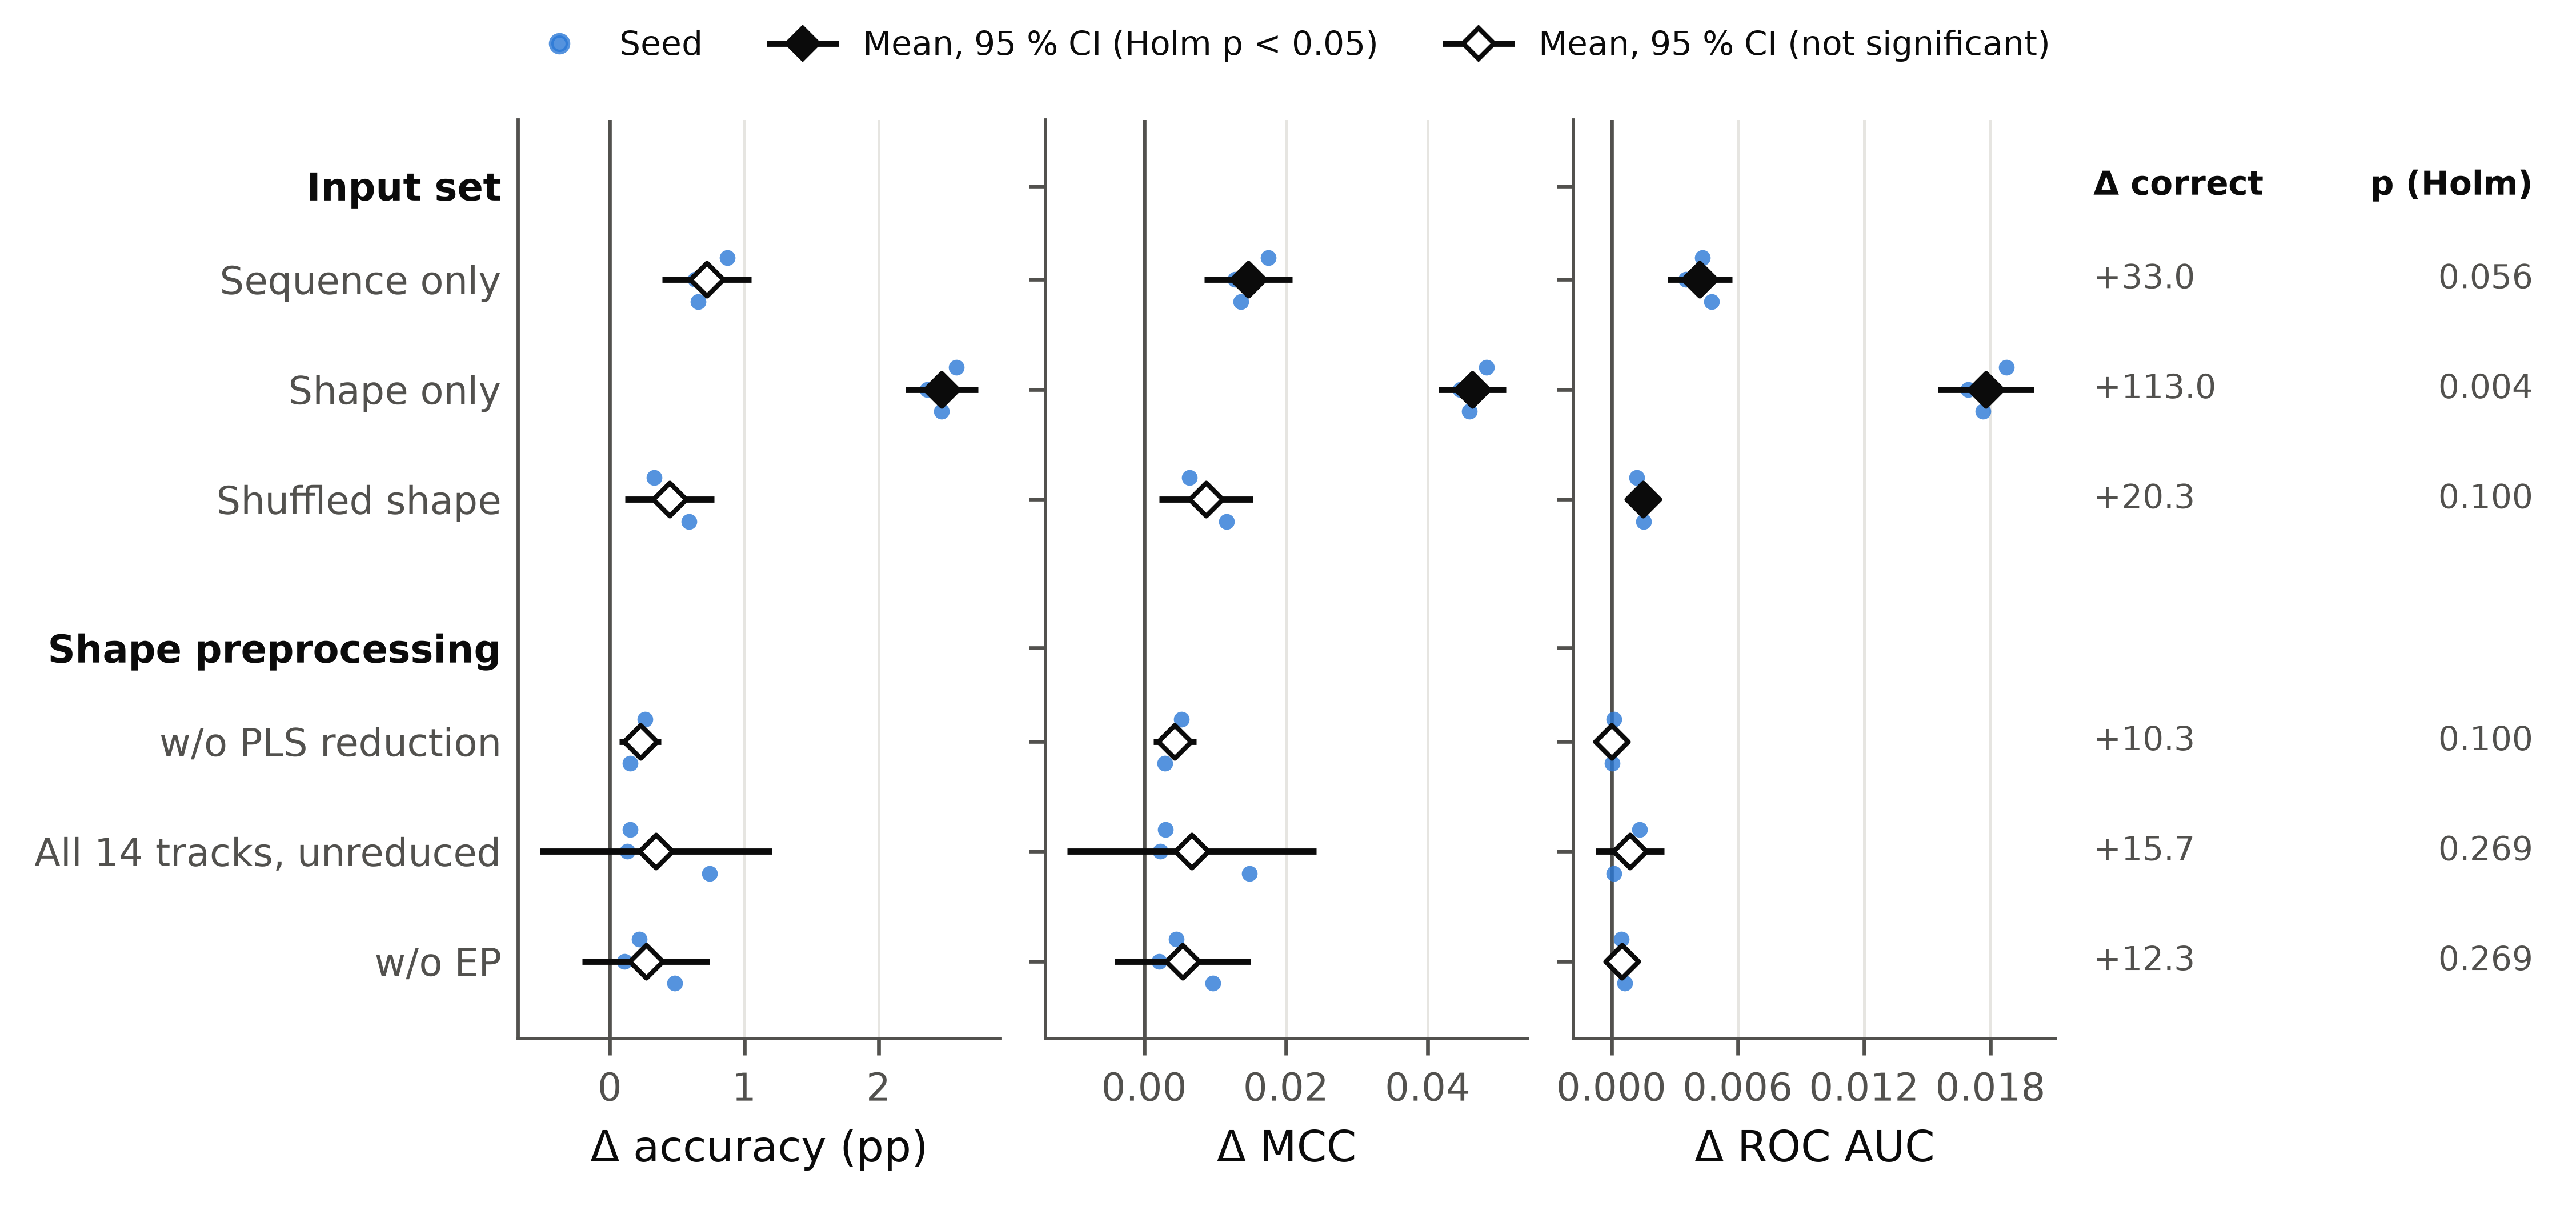

**boxplot_accuracy** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/modality/figures/boxplot_accuracy.png`  
Modality analysis: test accuracy of MorphoNup and of each variant on every outer test fold (3 seeds × folds; dots). Box: median and quartiles, whiskers 1.5 × IQR; diamond: mean; dashed line: MorphoNup mean. Fold-to-fold spread is larger than most differences, and folds of one seed share training rows, so the paired forest plot (deltas) carries the inference.

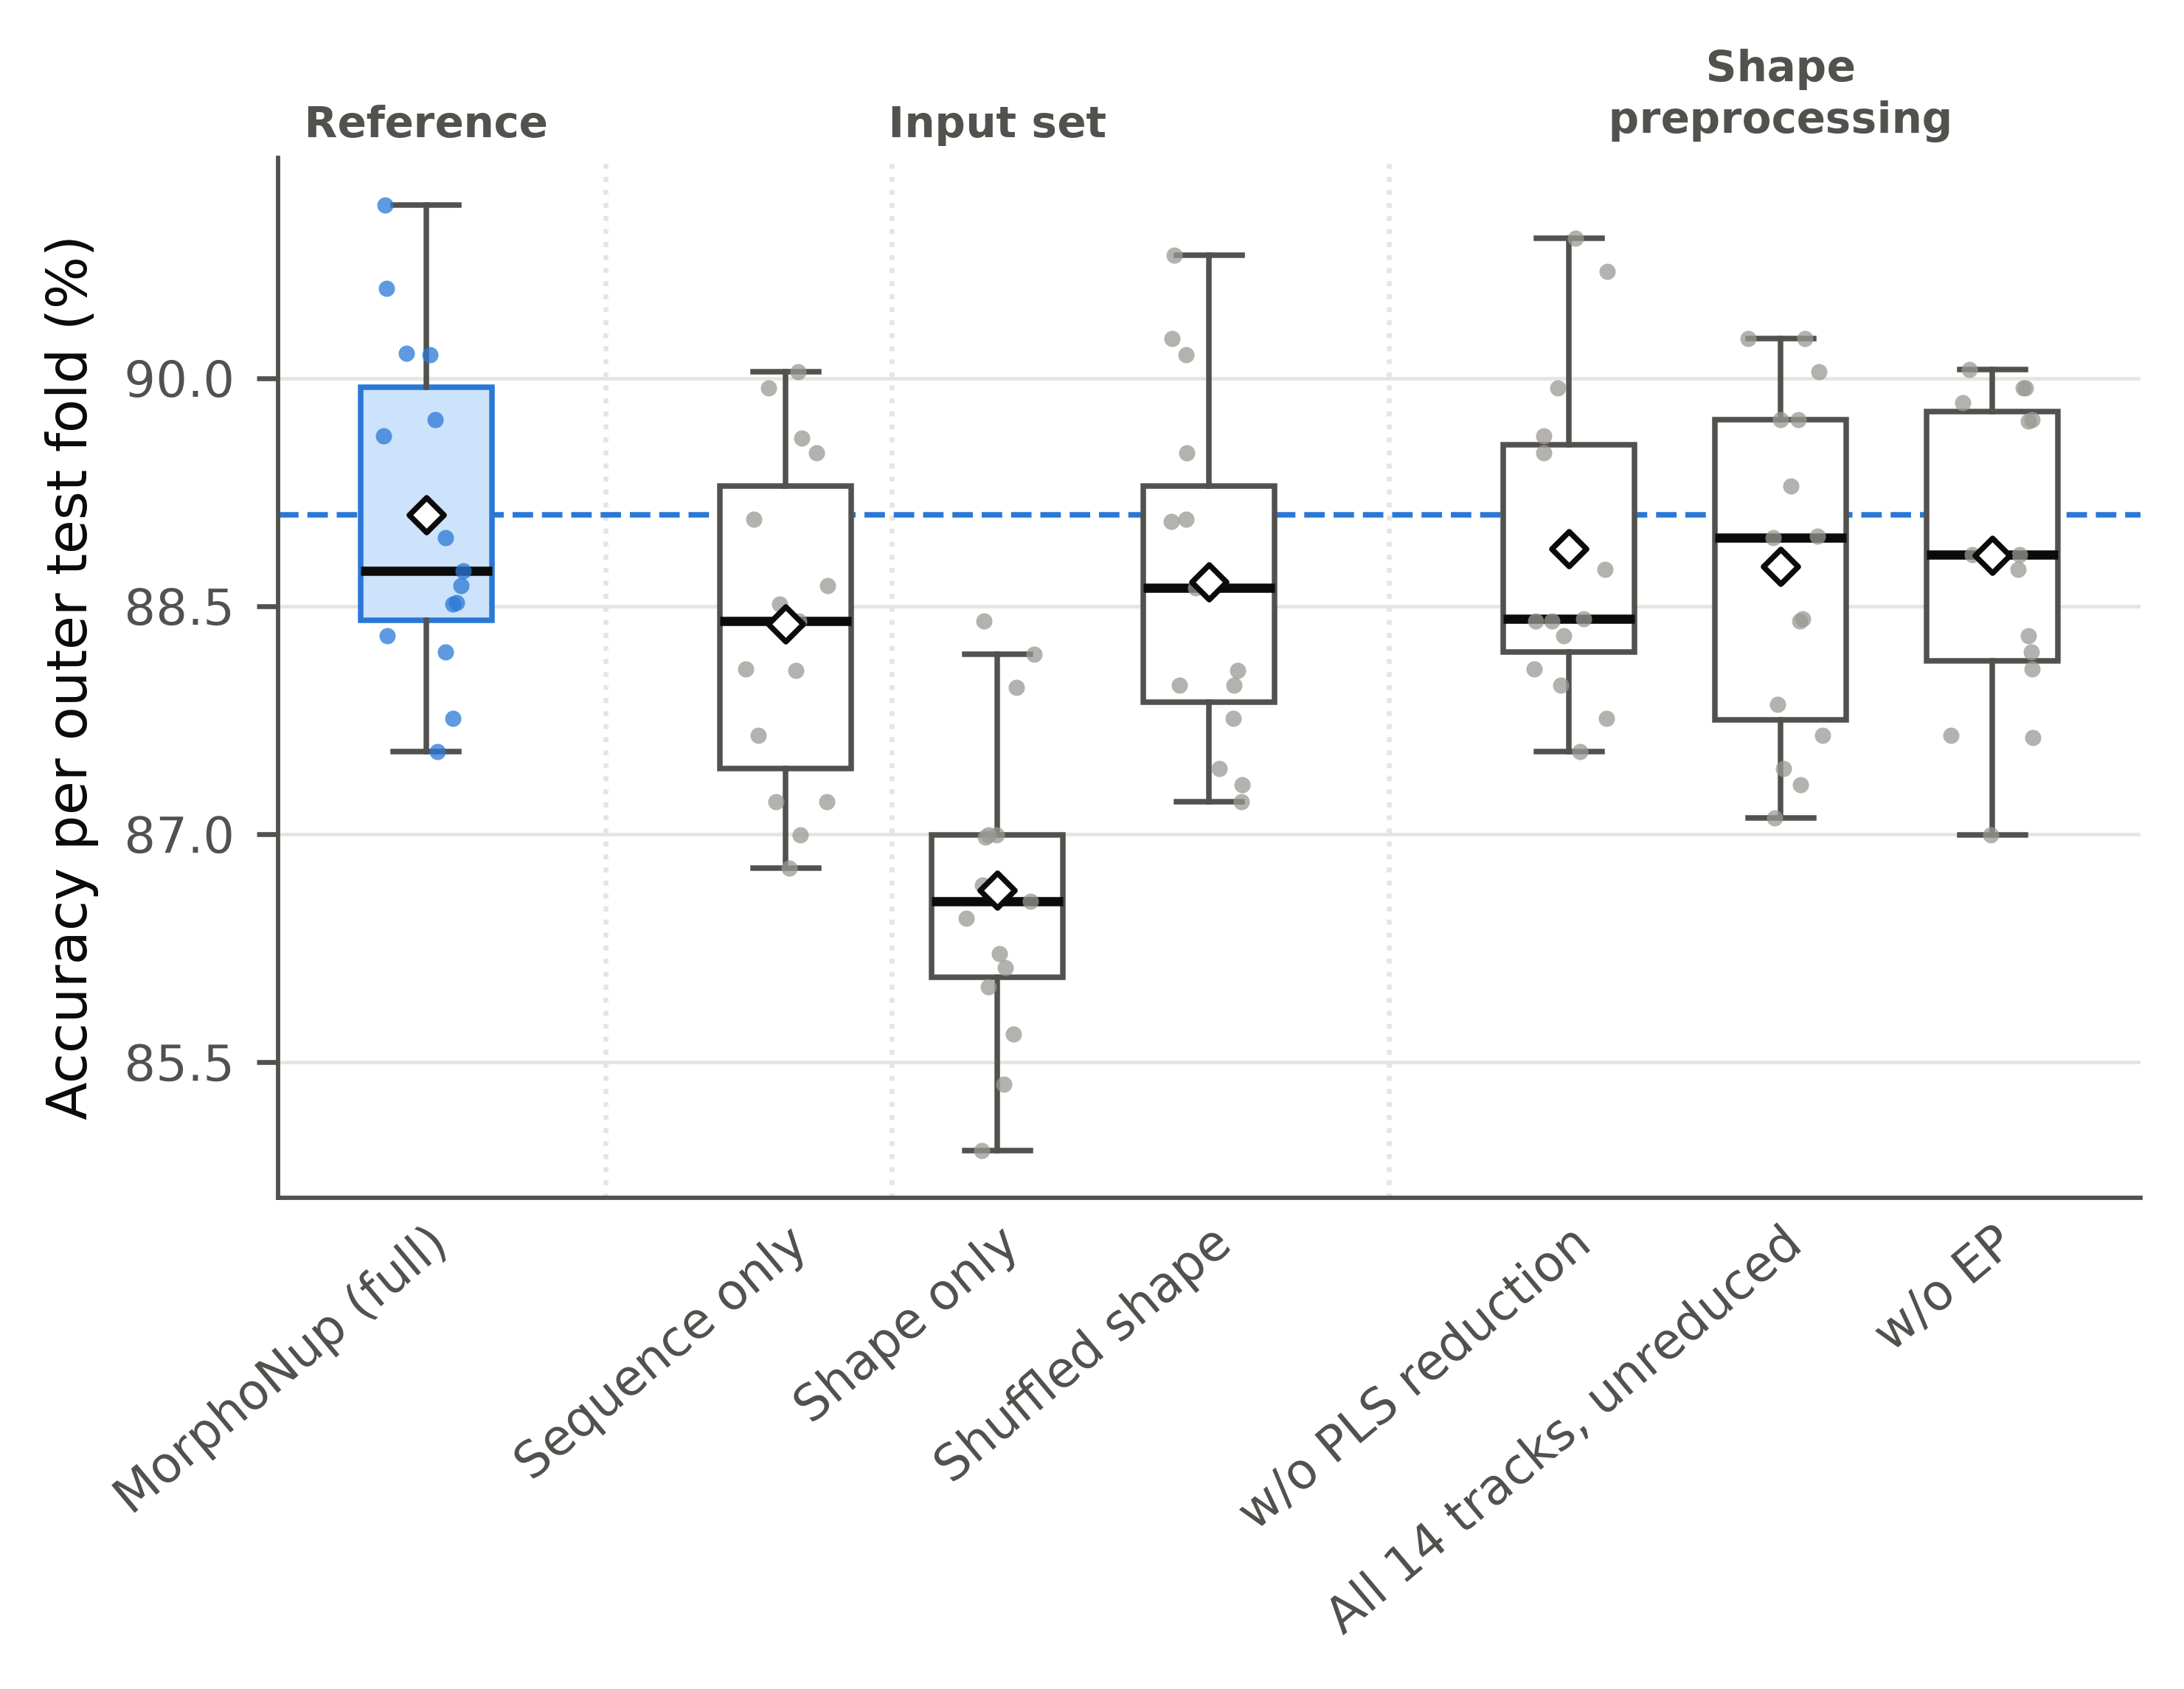

**roc_pr_arms** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/modality/figures/roc_pr_arms.png`  
Modality analysis, seed 151000: pooled out-of-fold ROC and precision-recall curves of MorphoNup and each input-set variant (legend: ROC AUC / average precision of this seed).

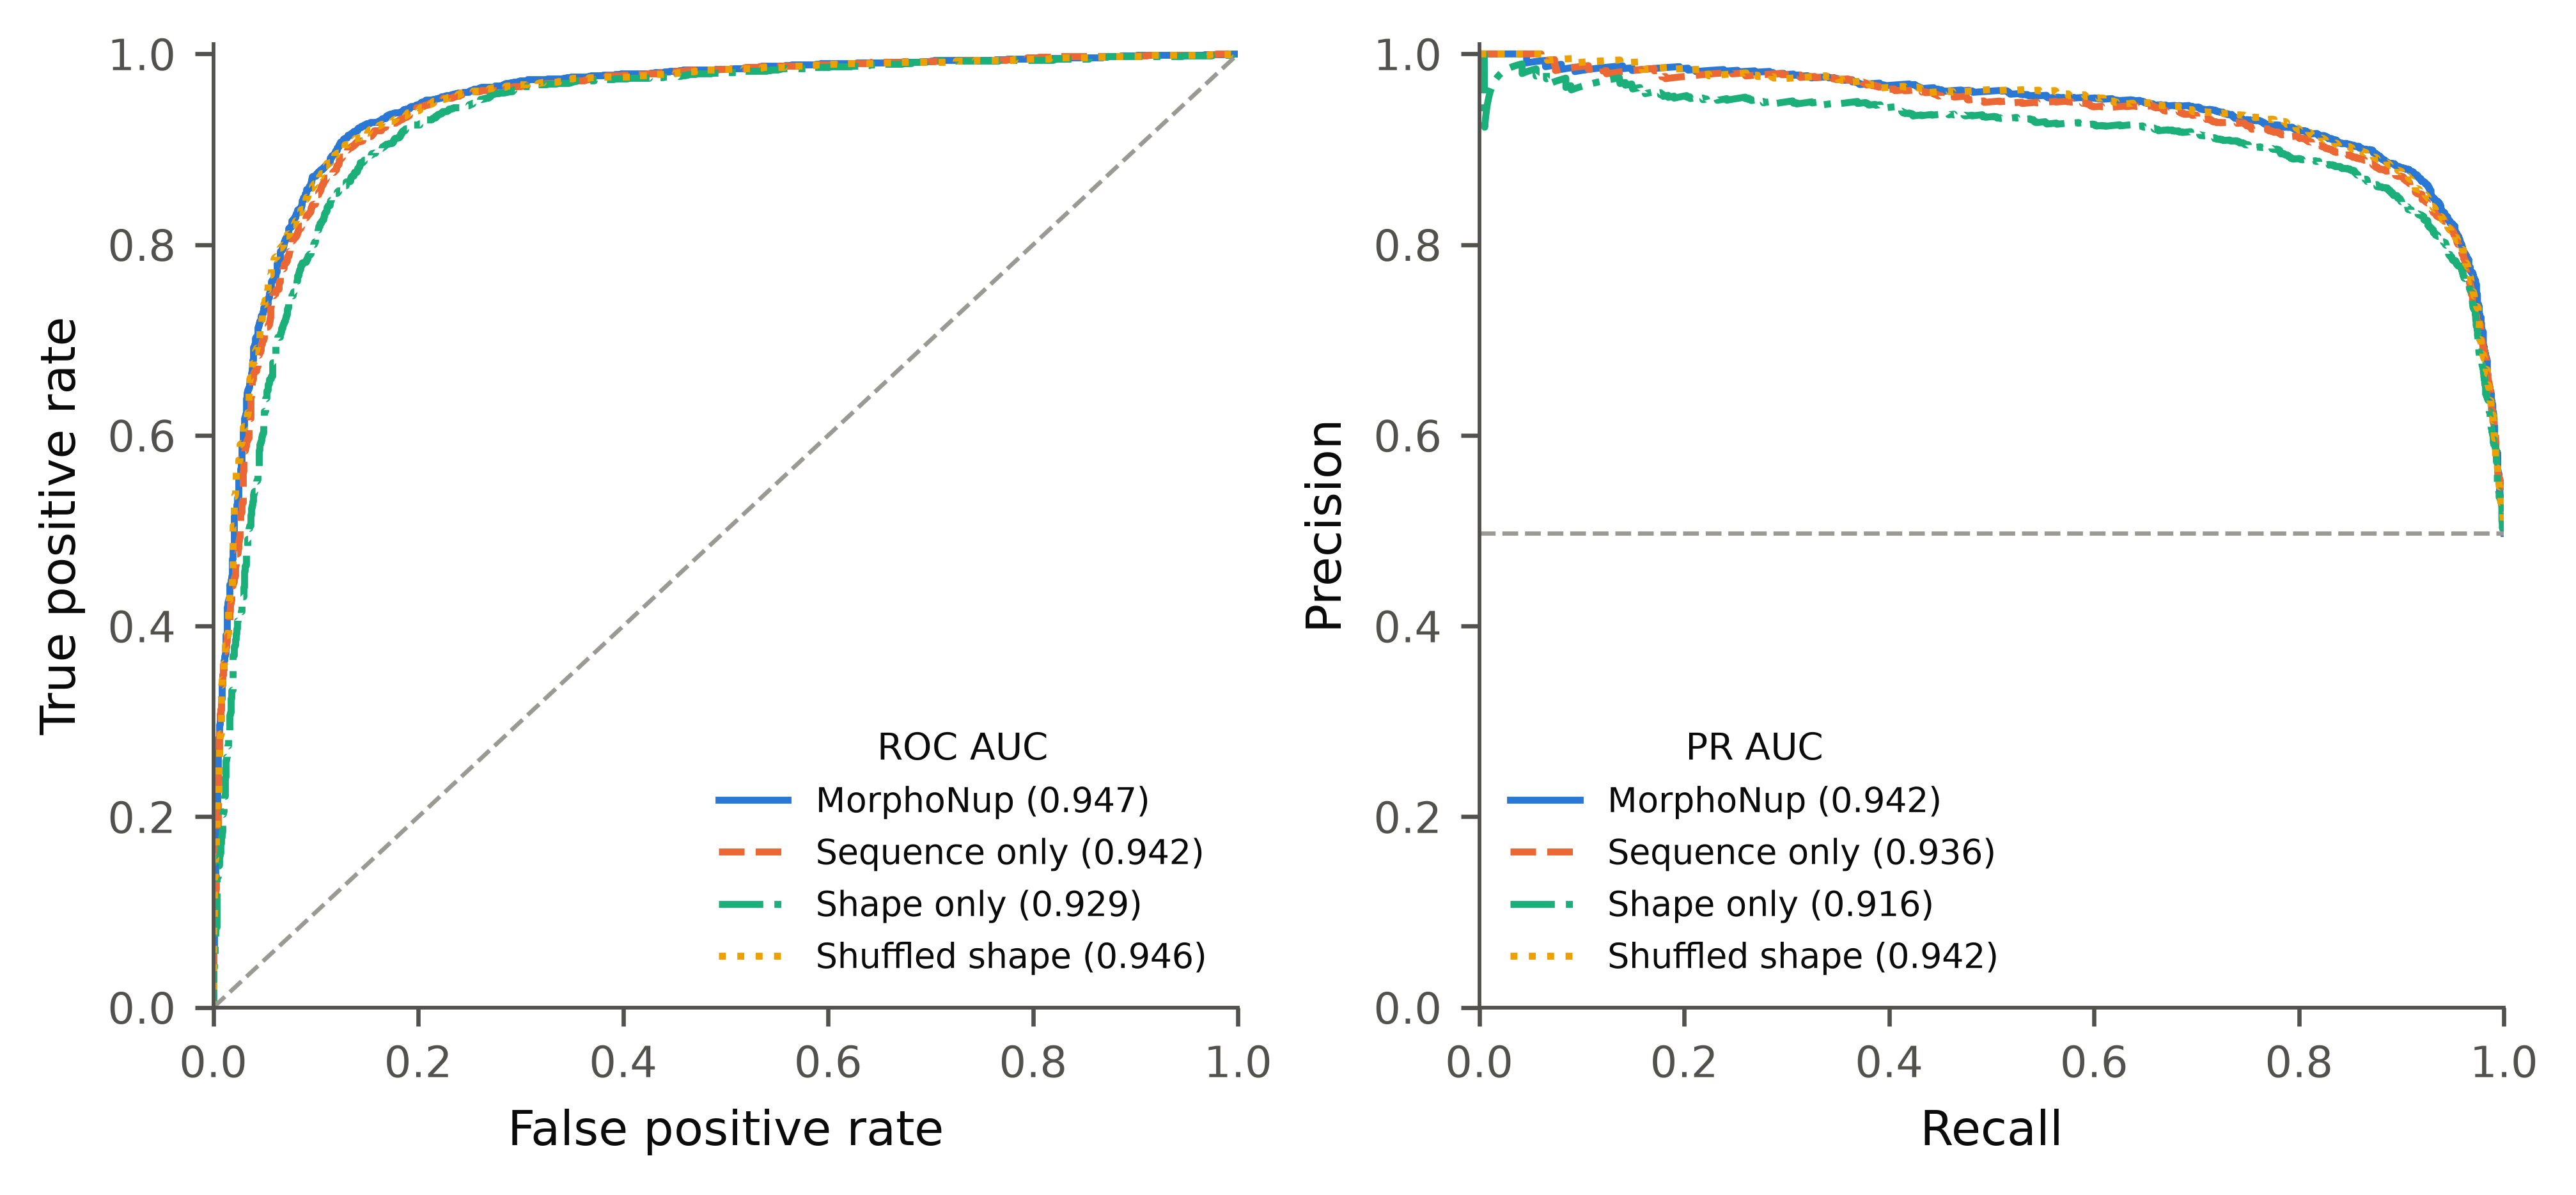

**delta_heatmap** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/modality/figures/delta_heatmap.png`  
Modality analysis: mean difference MorphoNup − variant for nine metrics (3 seeds; × 100). Blue: the variant is worse (what the variant lacks, scrambles or preprocesses differently helps); red: the variant is better; bold: the 95 % t interval over seeds excludes 0.

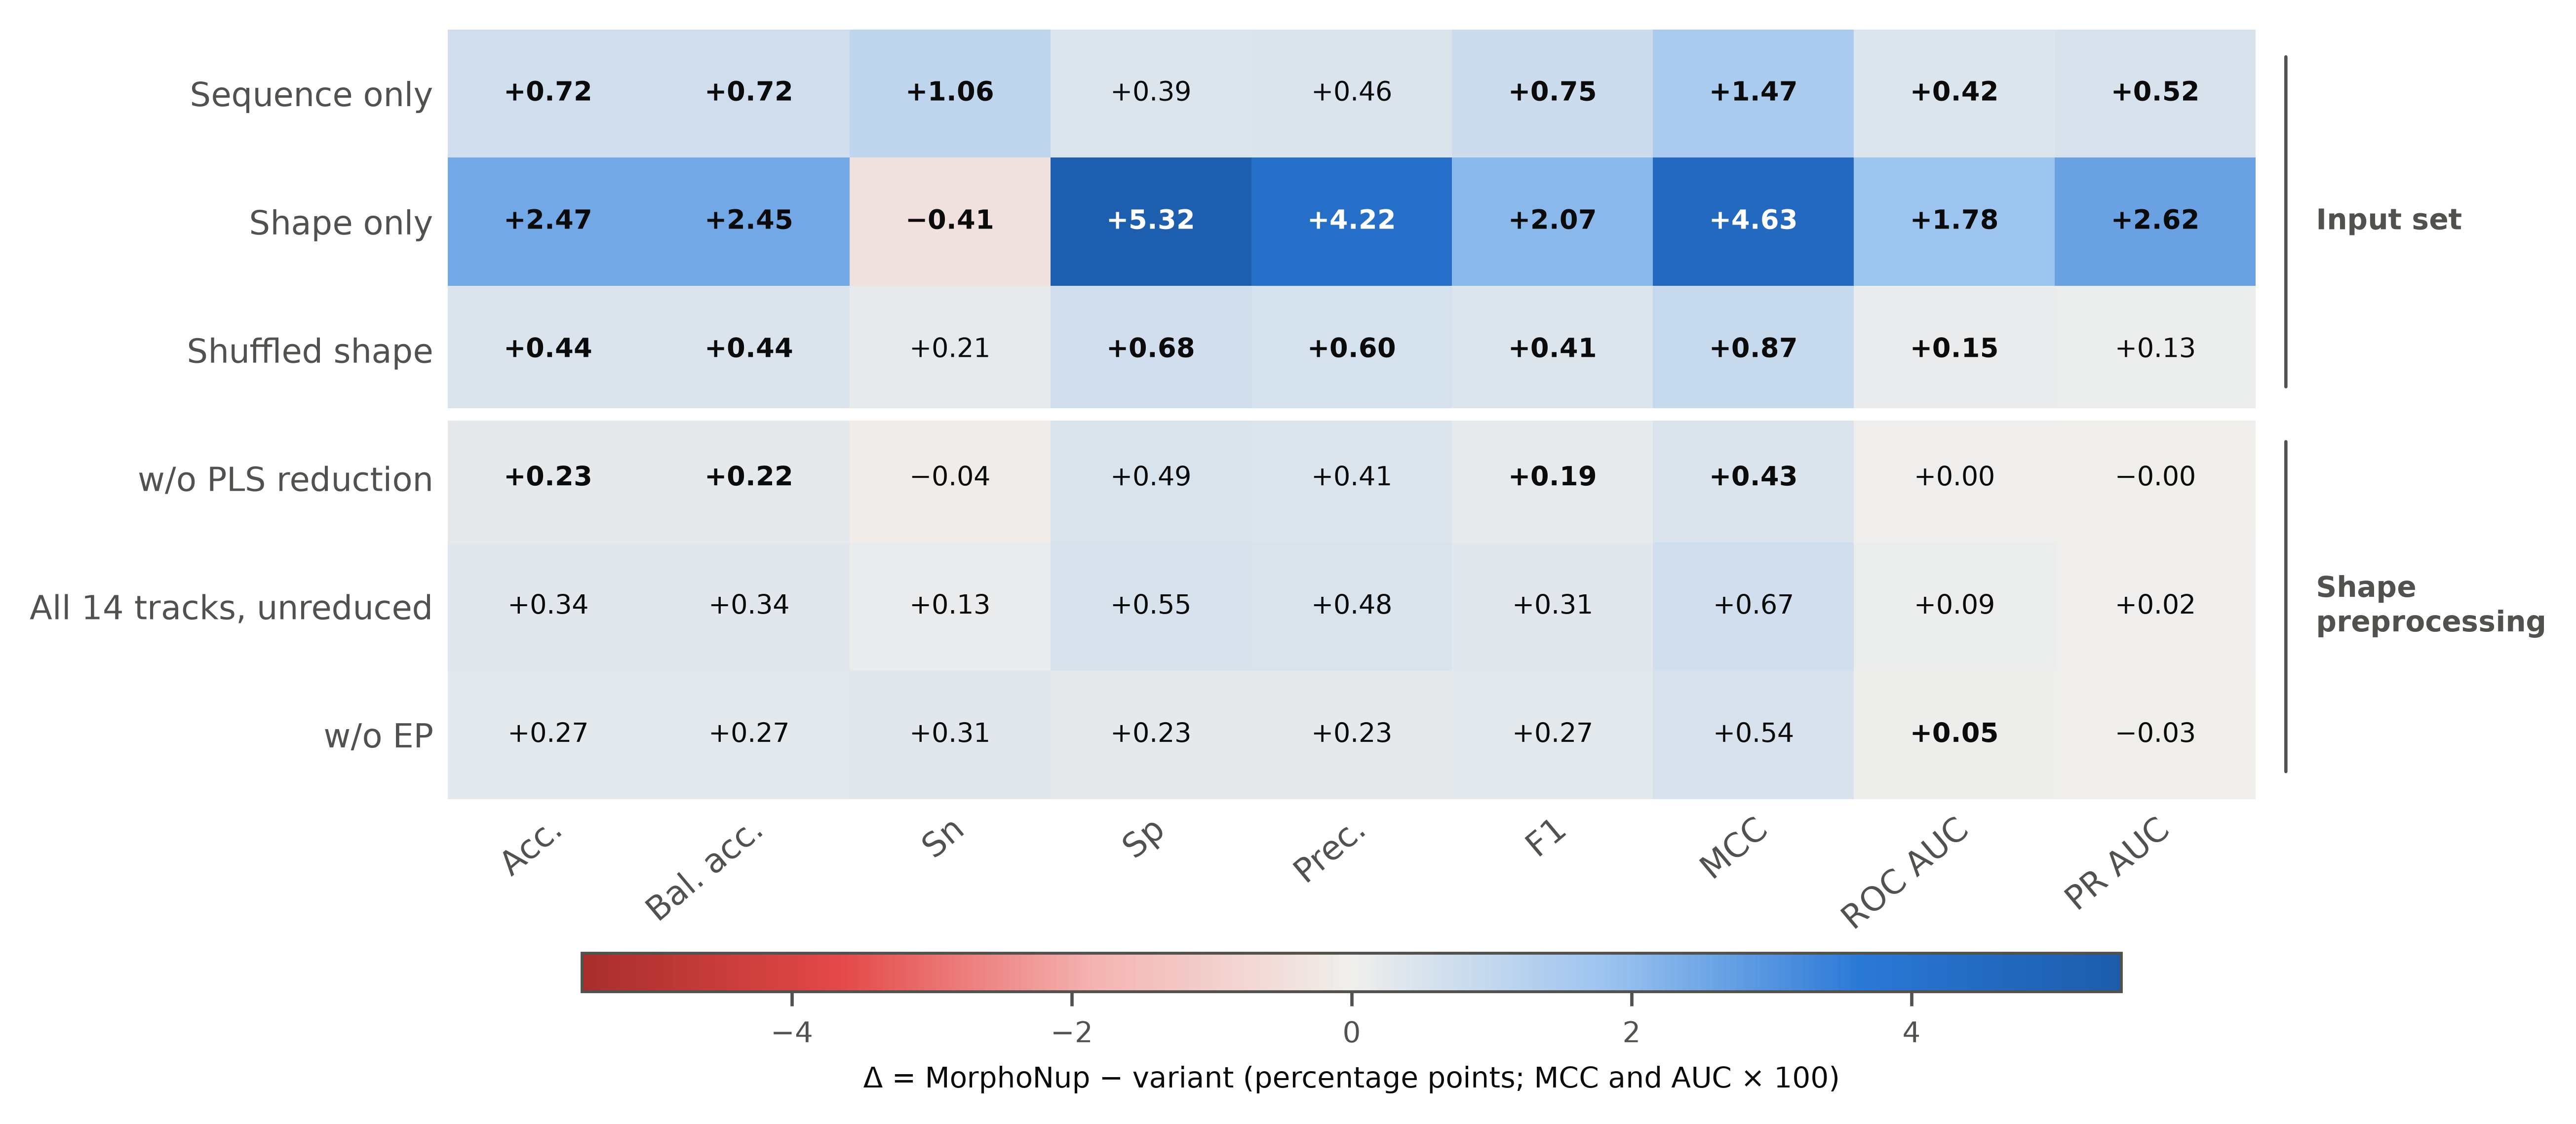

**metrics_panel** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/modality/figures/metrics_panel.png`  
Modality analysis: six pooled out-of-fold metrics of every variant (3 seeds; dots: seeds; tick: mean; bar: ± SD); dashed line and band: MorphoNup mean ± SD. Sensitivity = nucleosome recall, specificity = linker recall (threshold 0.5).

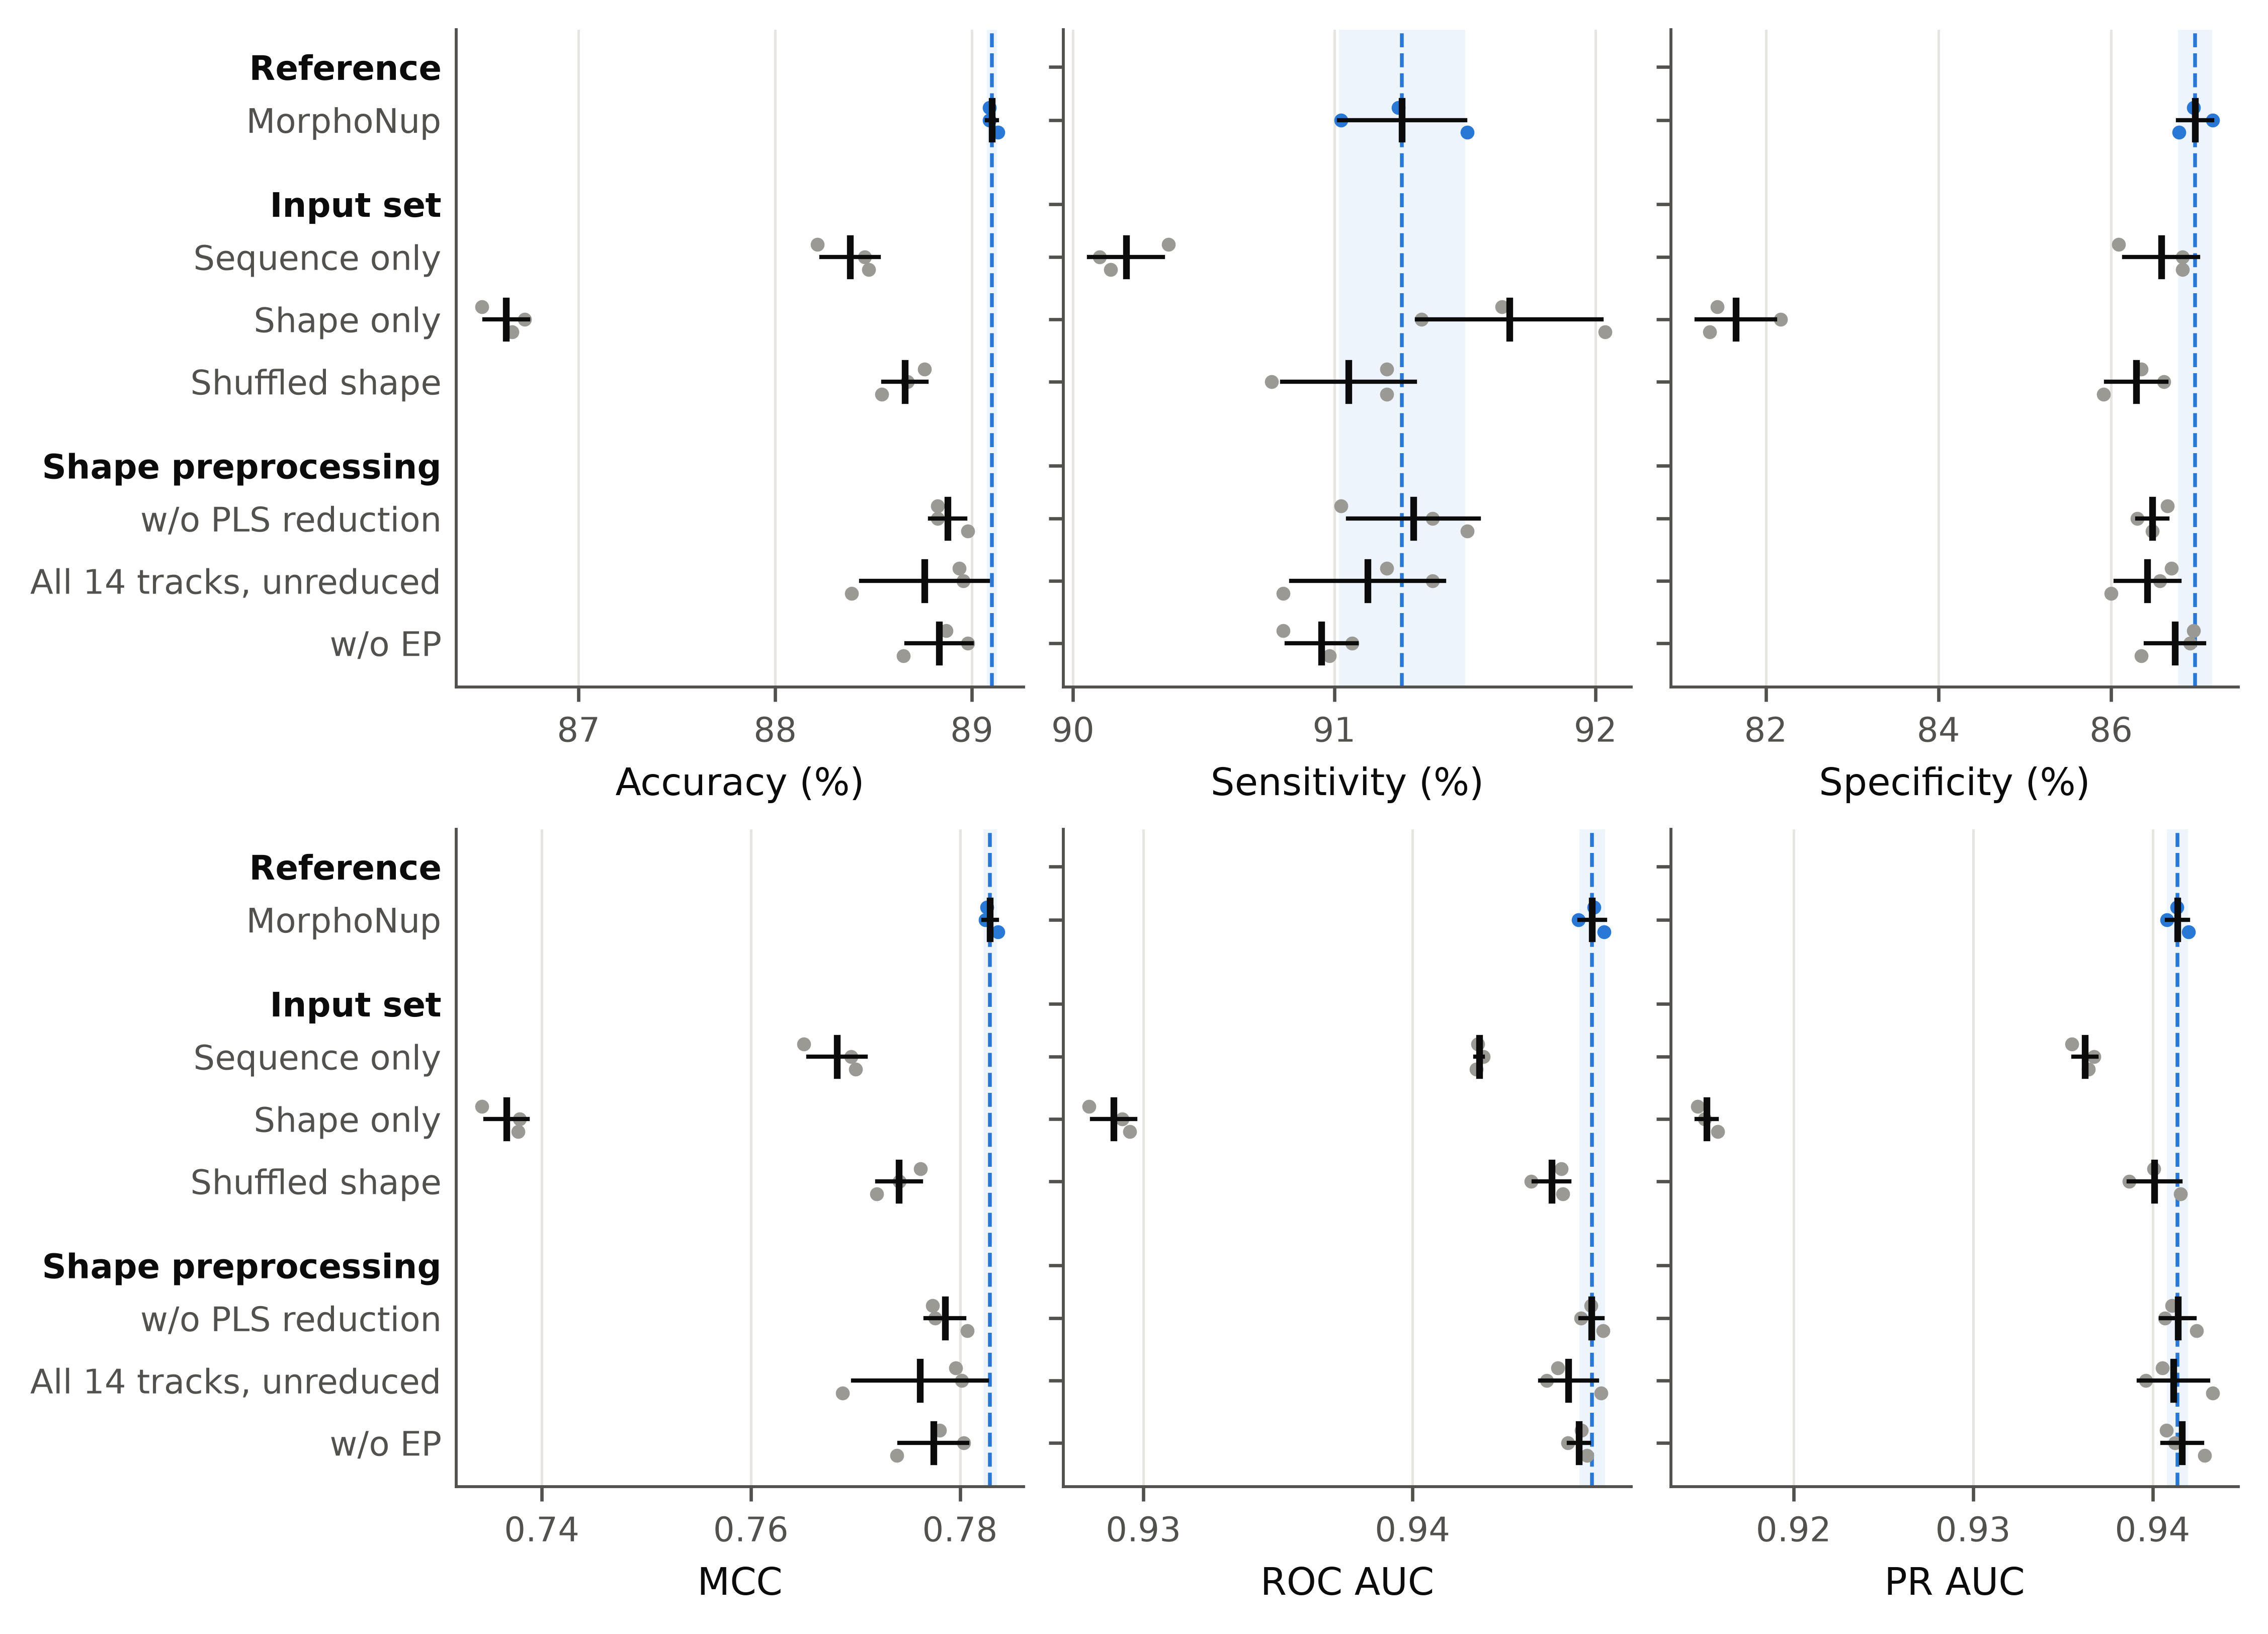

**accuracy** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/modality/figures/accuracy.png`  
Modality analysis: pooled out-of-fold accuracy of each variant (dots: seeds; tick: mean; bar: ± SD); dashed line and band: MorphoNup mean ± SD.

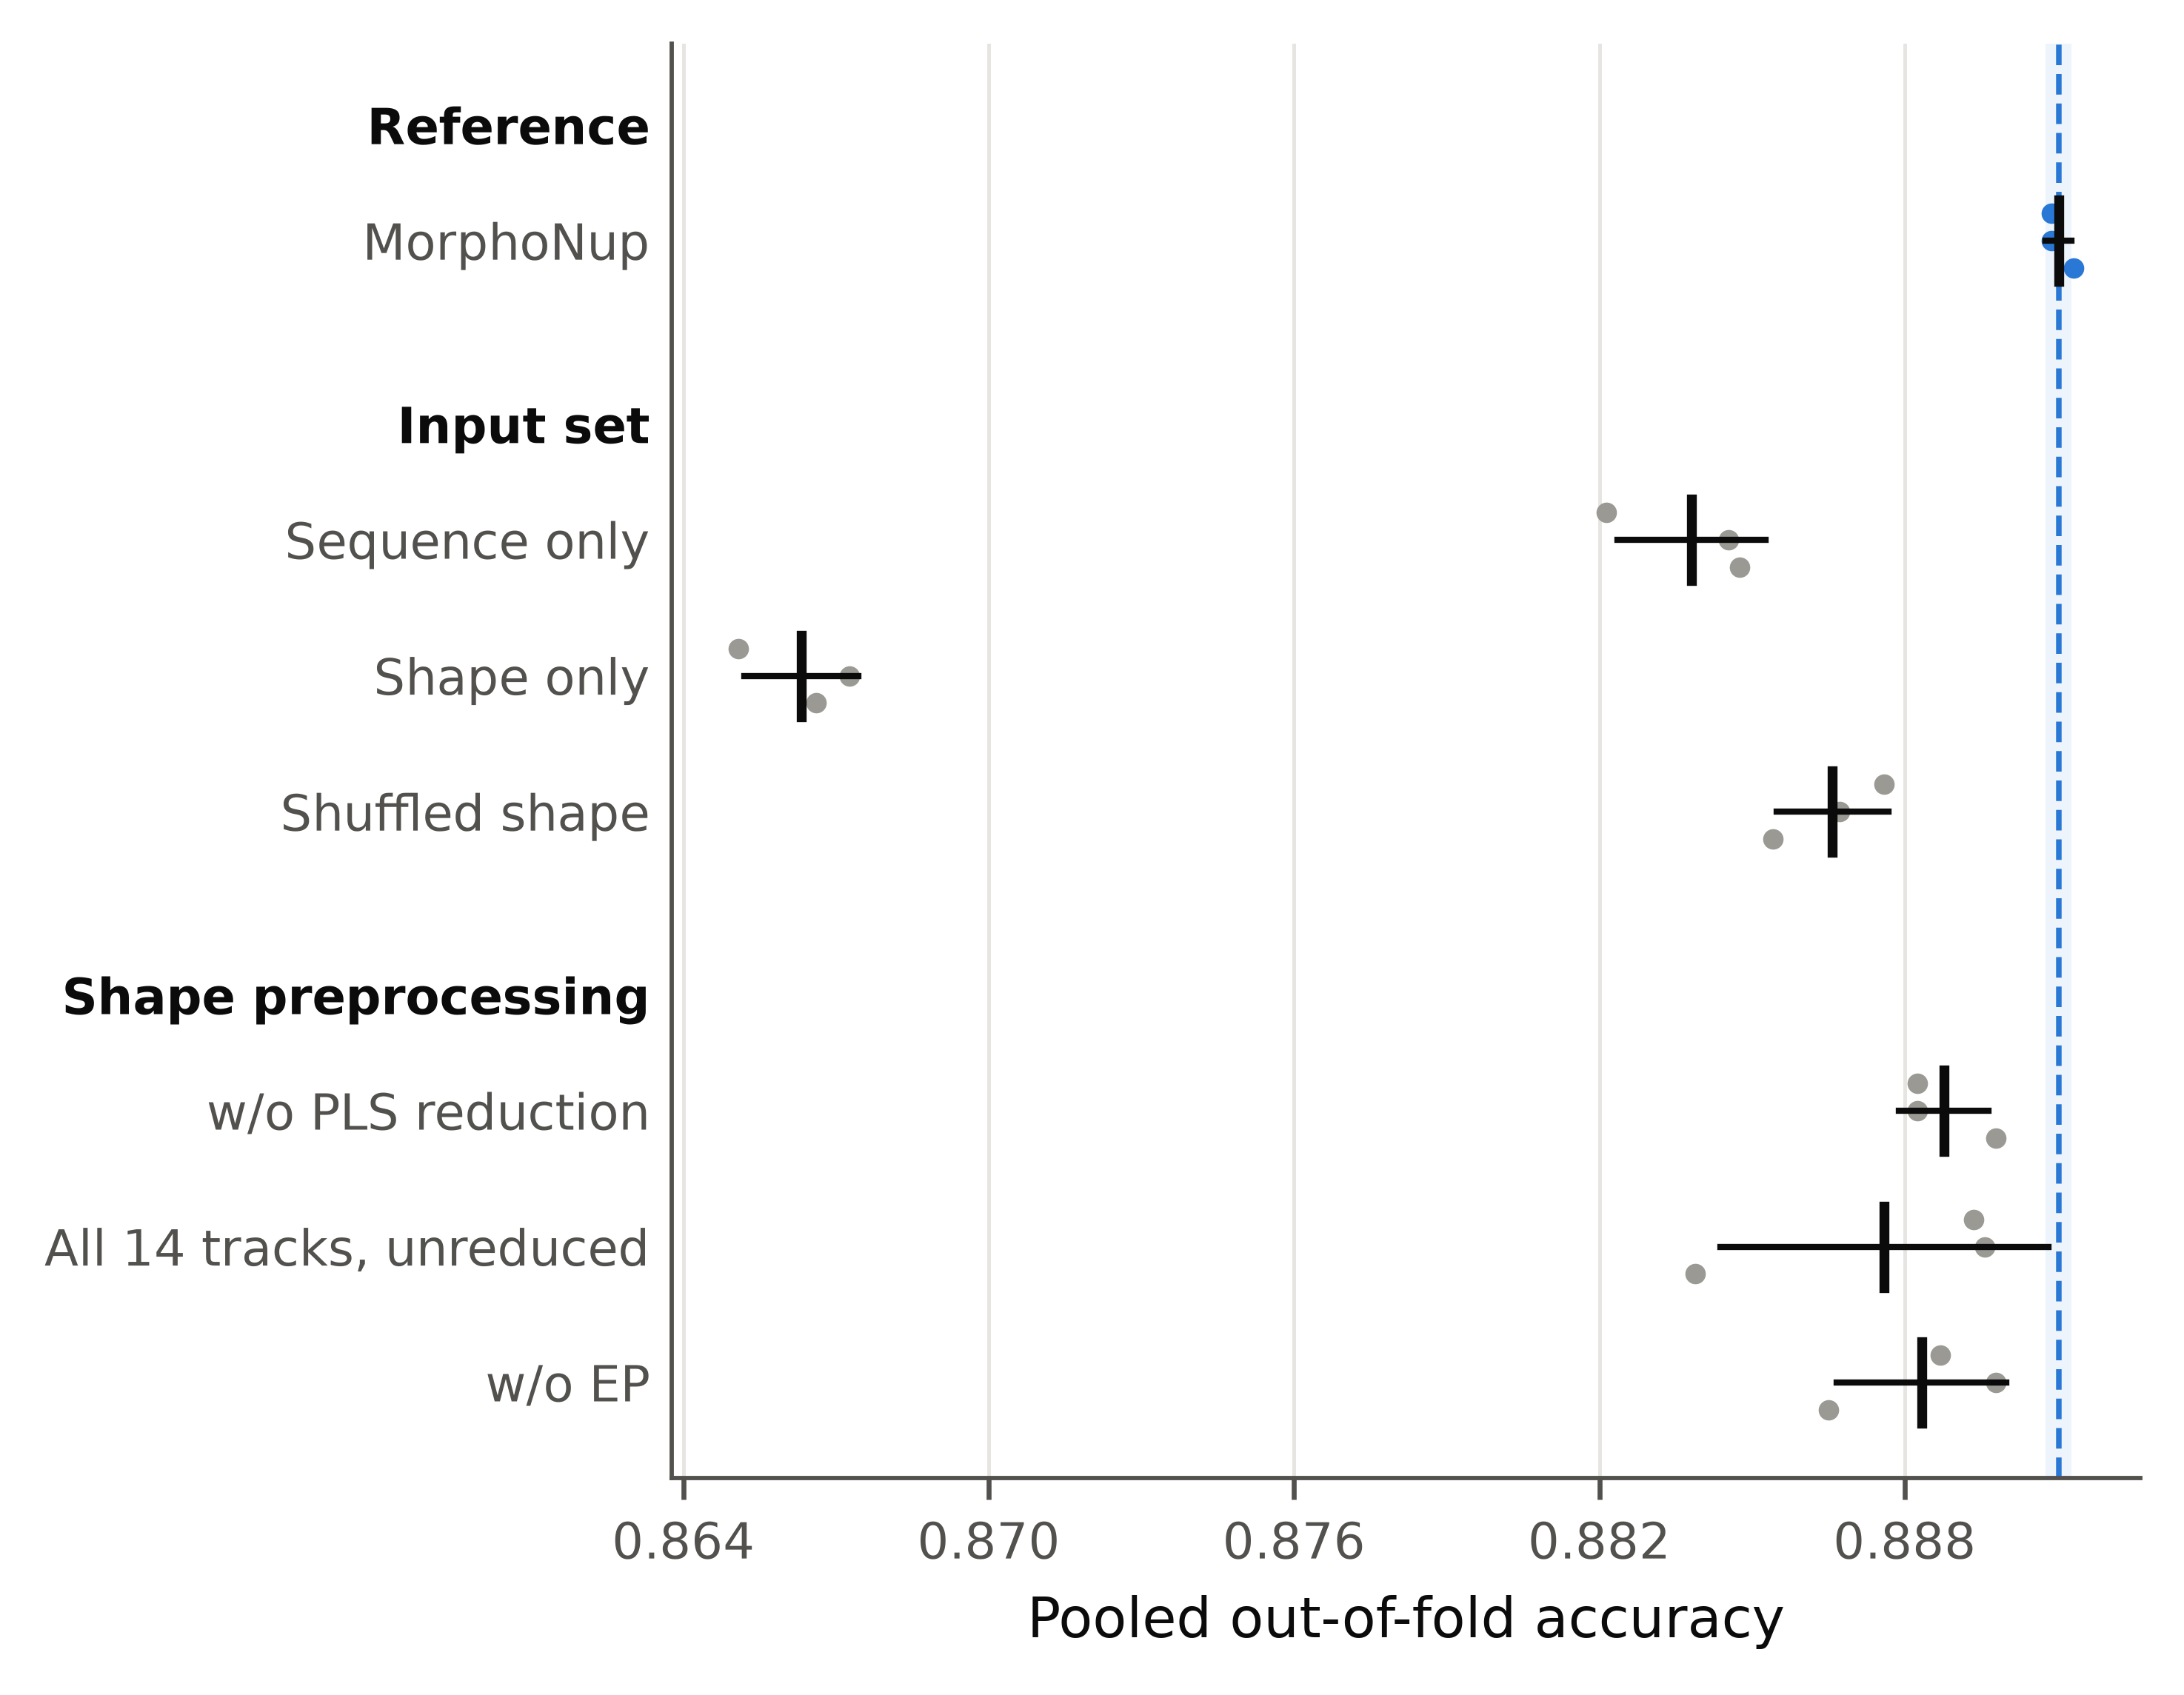

**discordance** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/modality/figures/discordance.png`  
Modality analysis: the discordant test sequences behind the McNemar test, mean per seed (3 seeds). Blue: classified correctly by MorphoNup only; red: by the variant only; net = blue − red = difference in correct sequences.

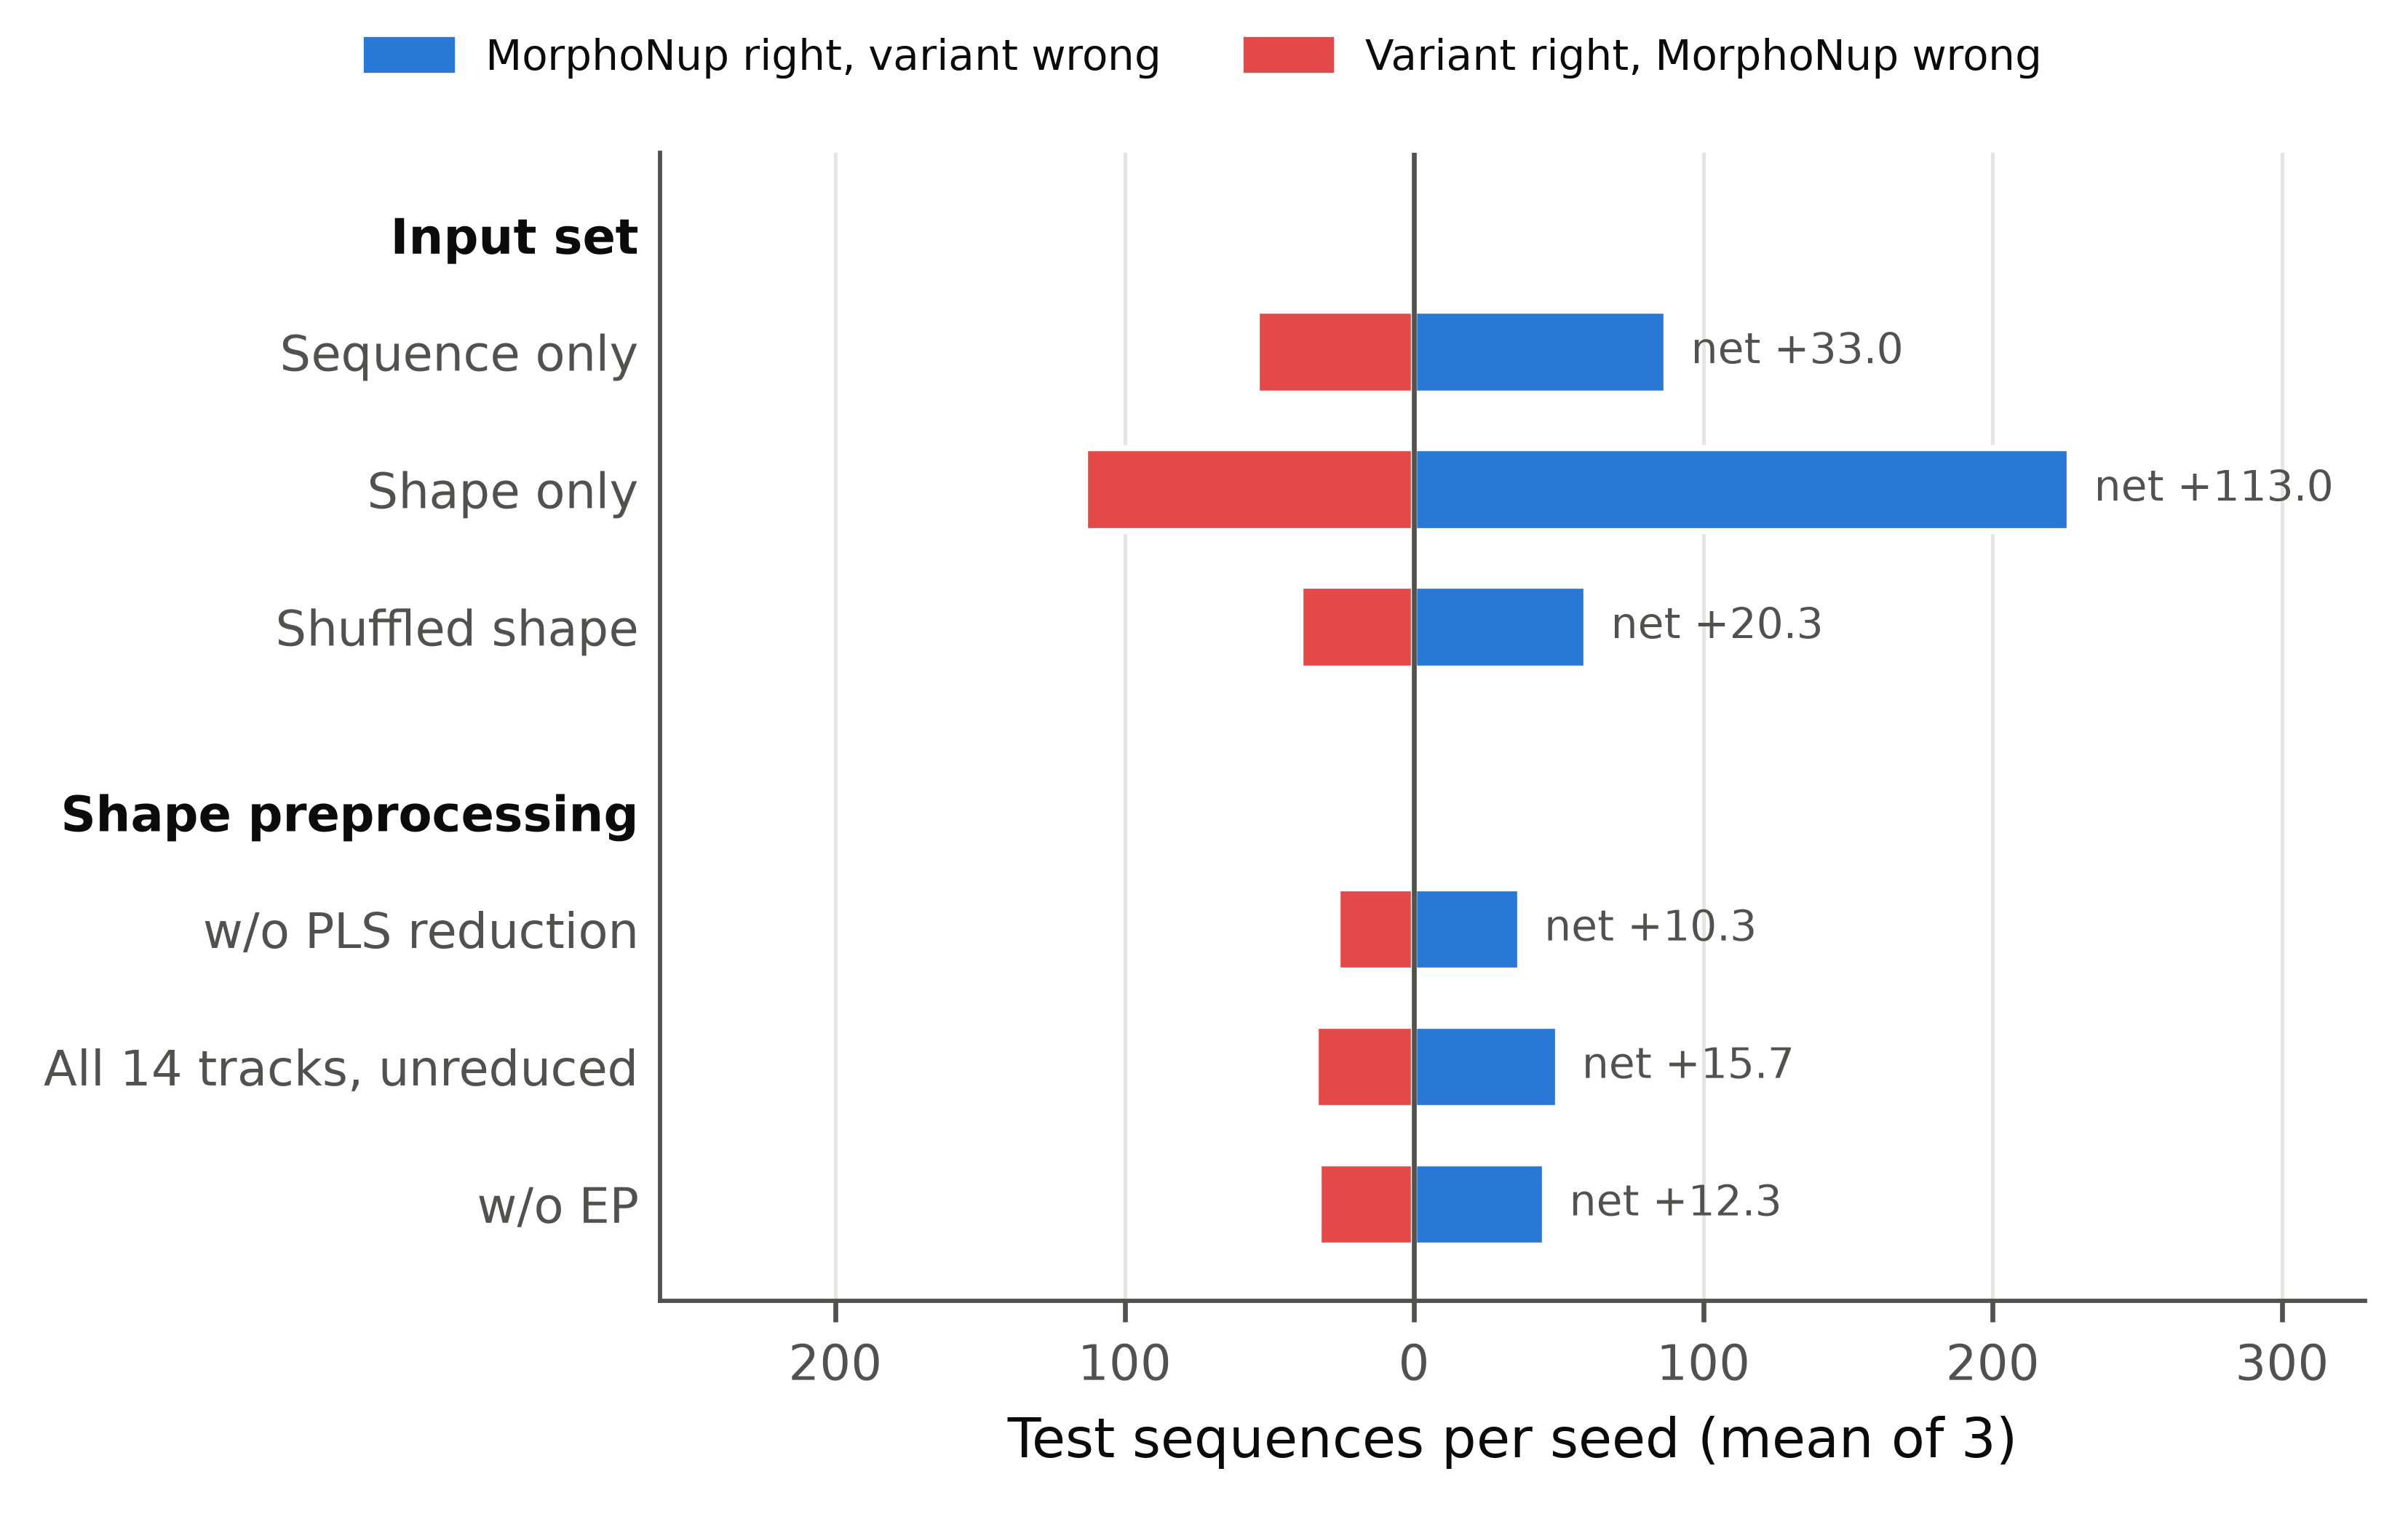

**fold_deltas** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/modality/figures/fold_deltas.png`  
Modality analysis: MorphoNup minus variant accuracy on each outer test fold of each seed (dots; box: median and quartiles, whiskers 1.5 × IQR). Folds of one seed share training rows and fold-to-fold noise is large, so this panel is descriptive; inference uses the seed-level test.

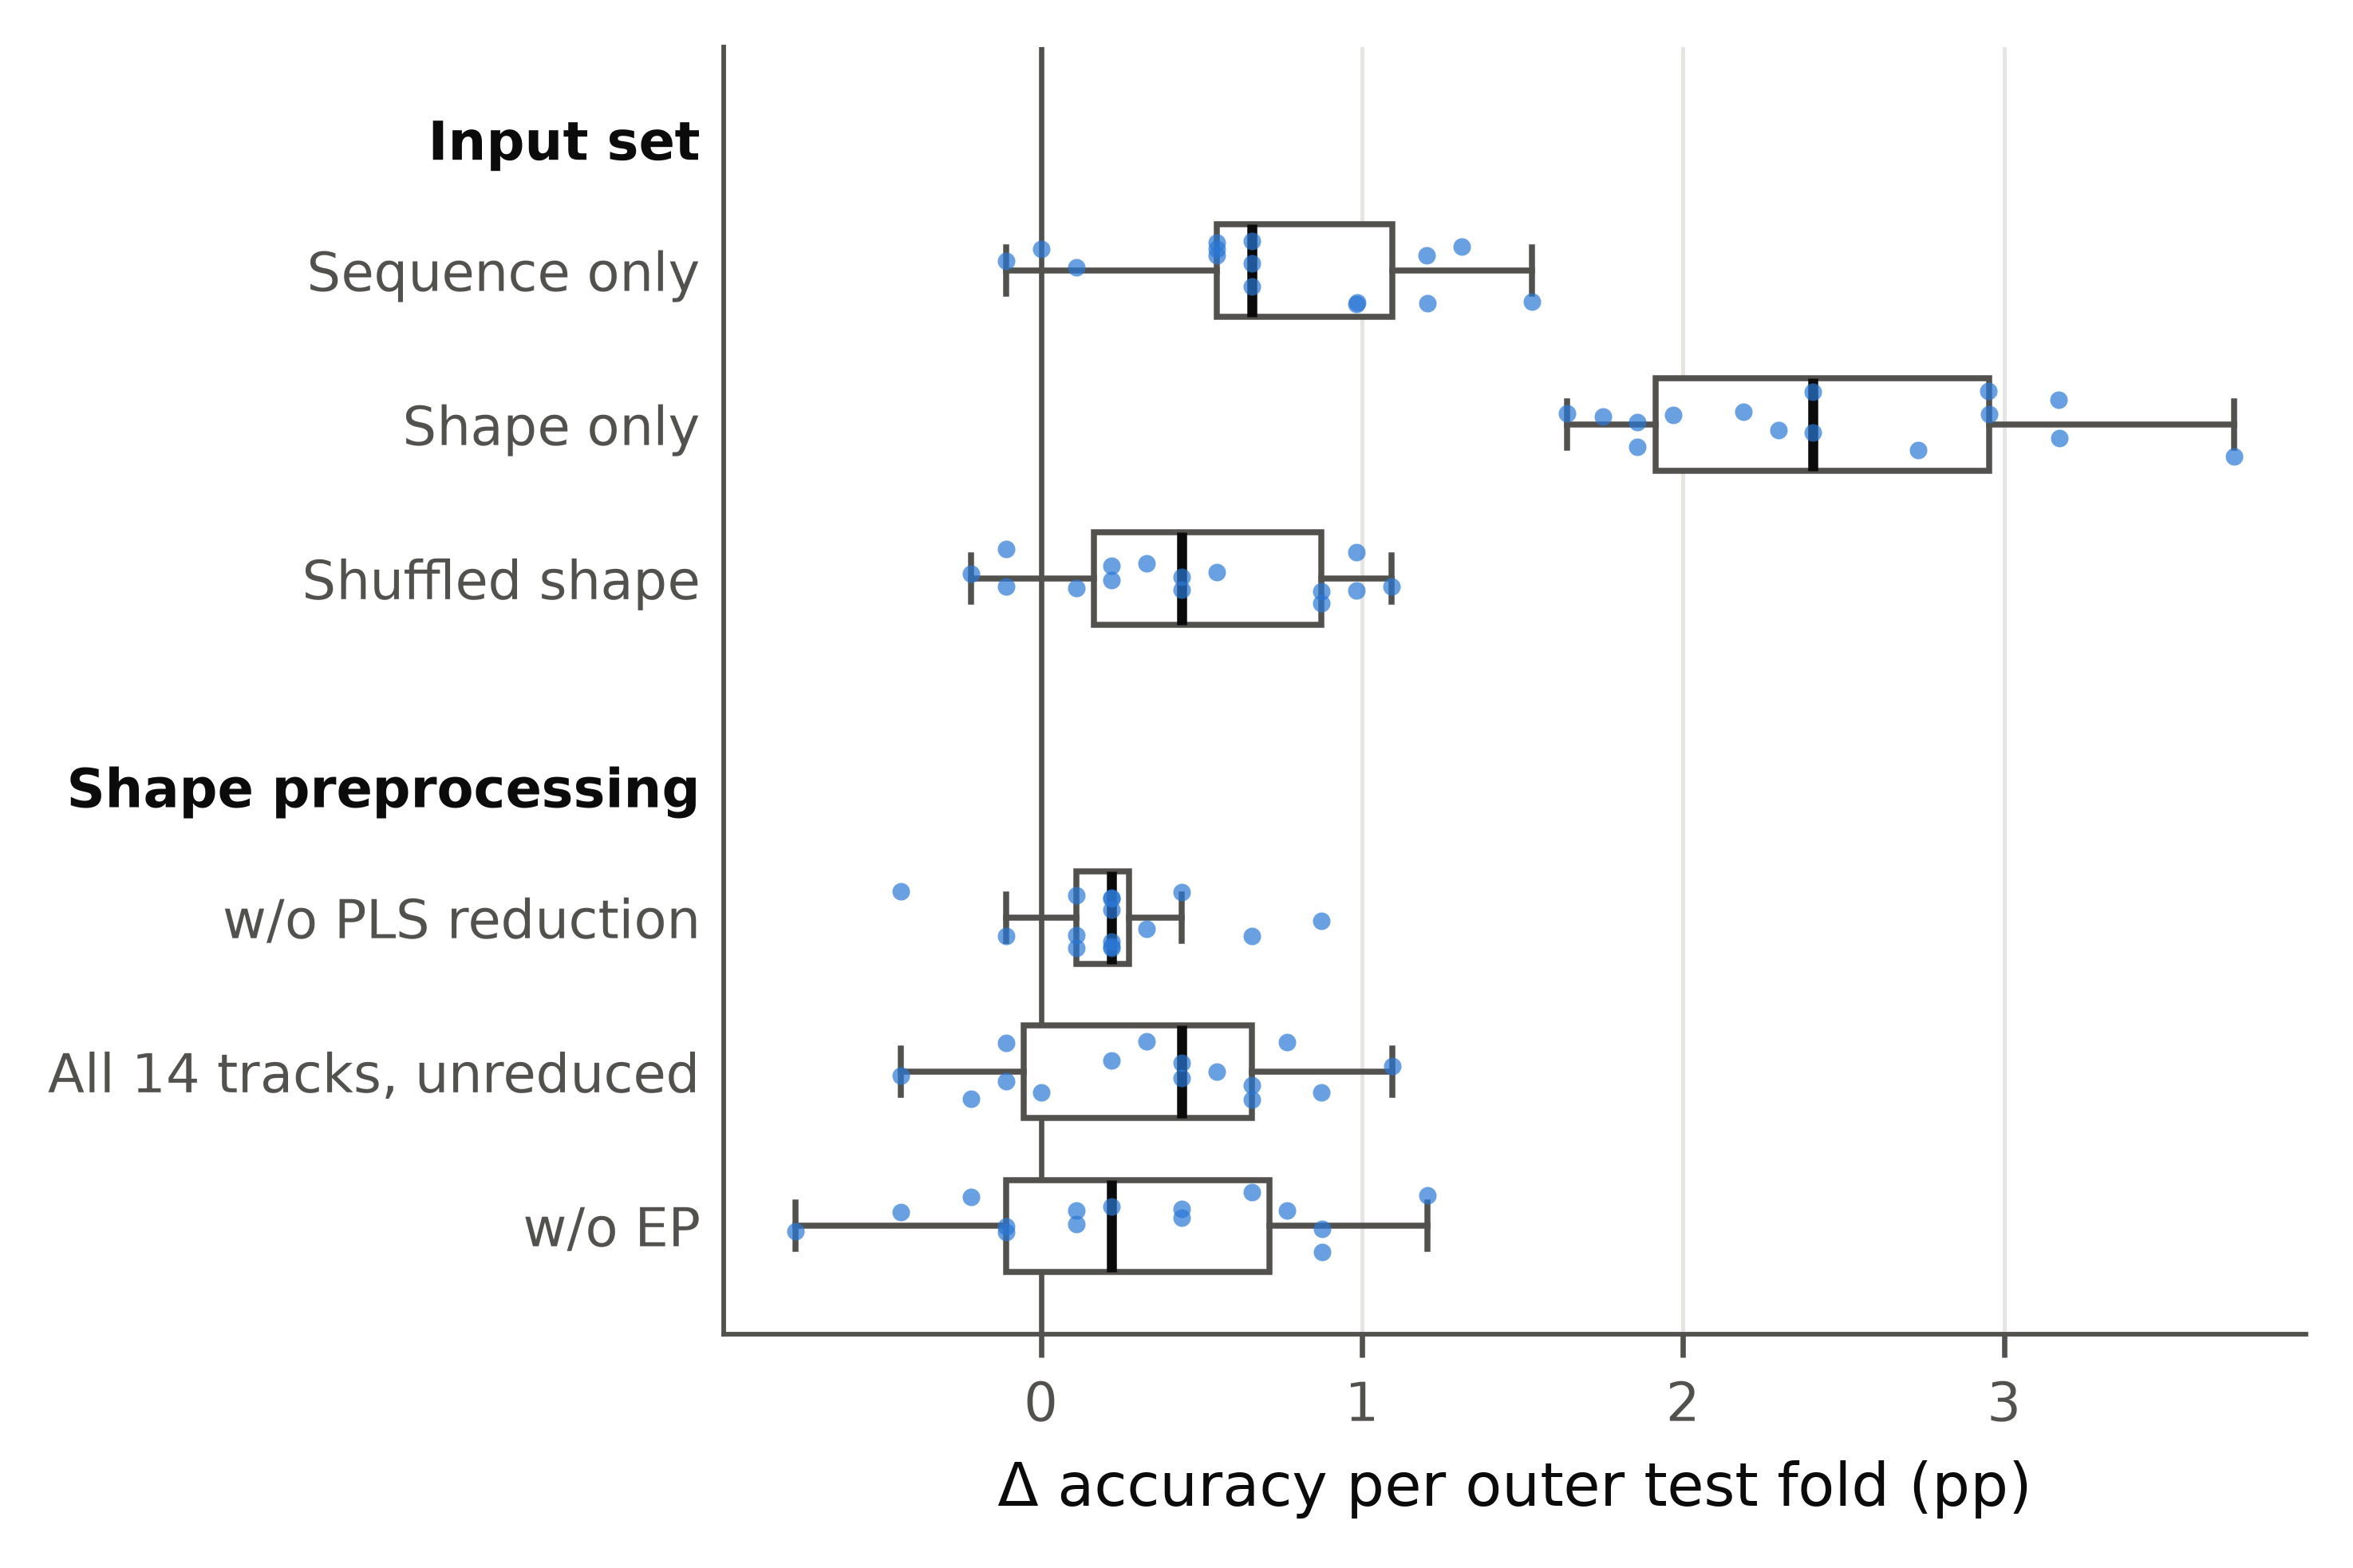

**roc_pr_parts** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/modality/figures/roc_pr_parts.png`  
Modality analysis: pooled out-of-fold ROC (top) and precision–recall (bottom) curves of MorphoNup and the variants of each part, seed 151000, axes zoomed to the upper-left (ROC) and upper-right (PR) region where the curves separate; legend: ROC AUC / average precision, mean over seeds. Differences of a few thousandths of AUC are hard to see as curves; the forest plot and tables give them.

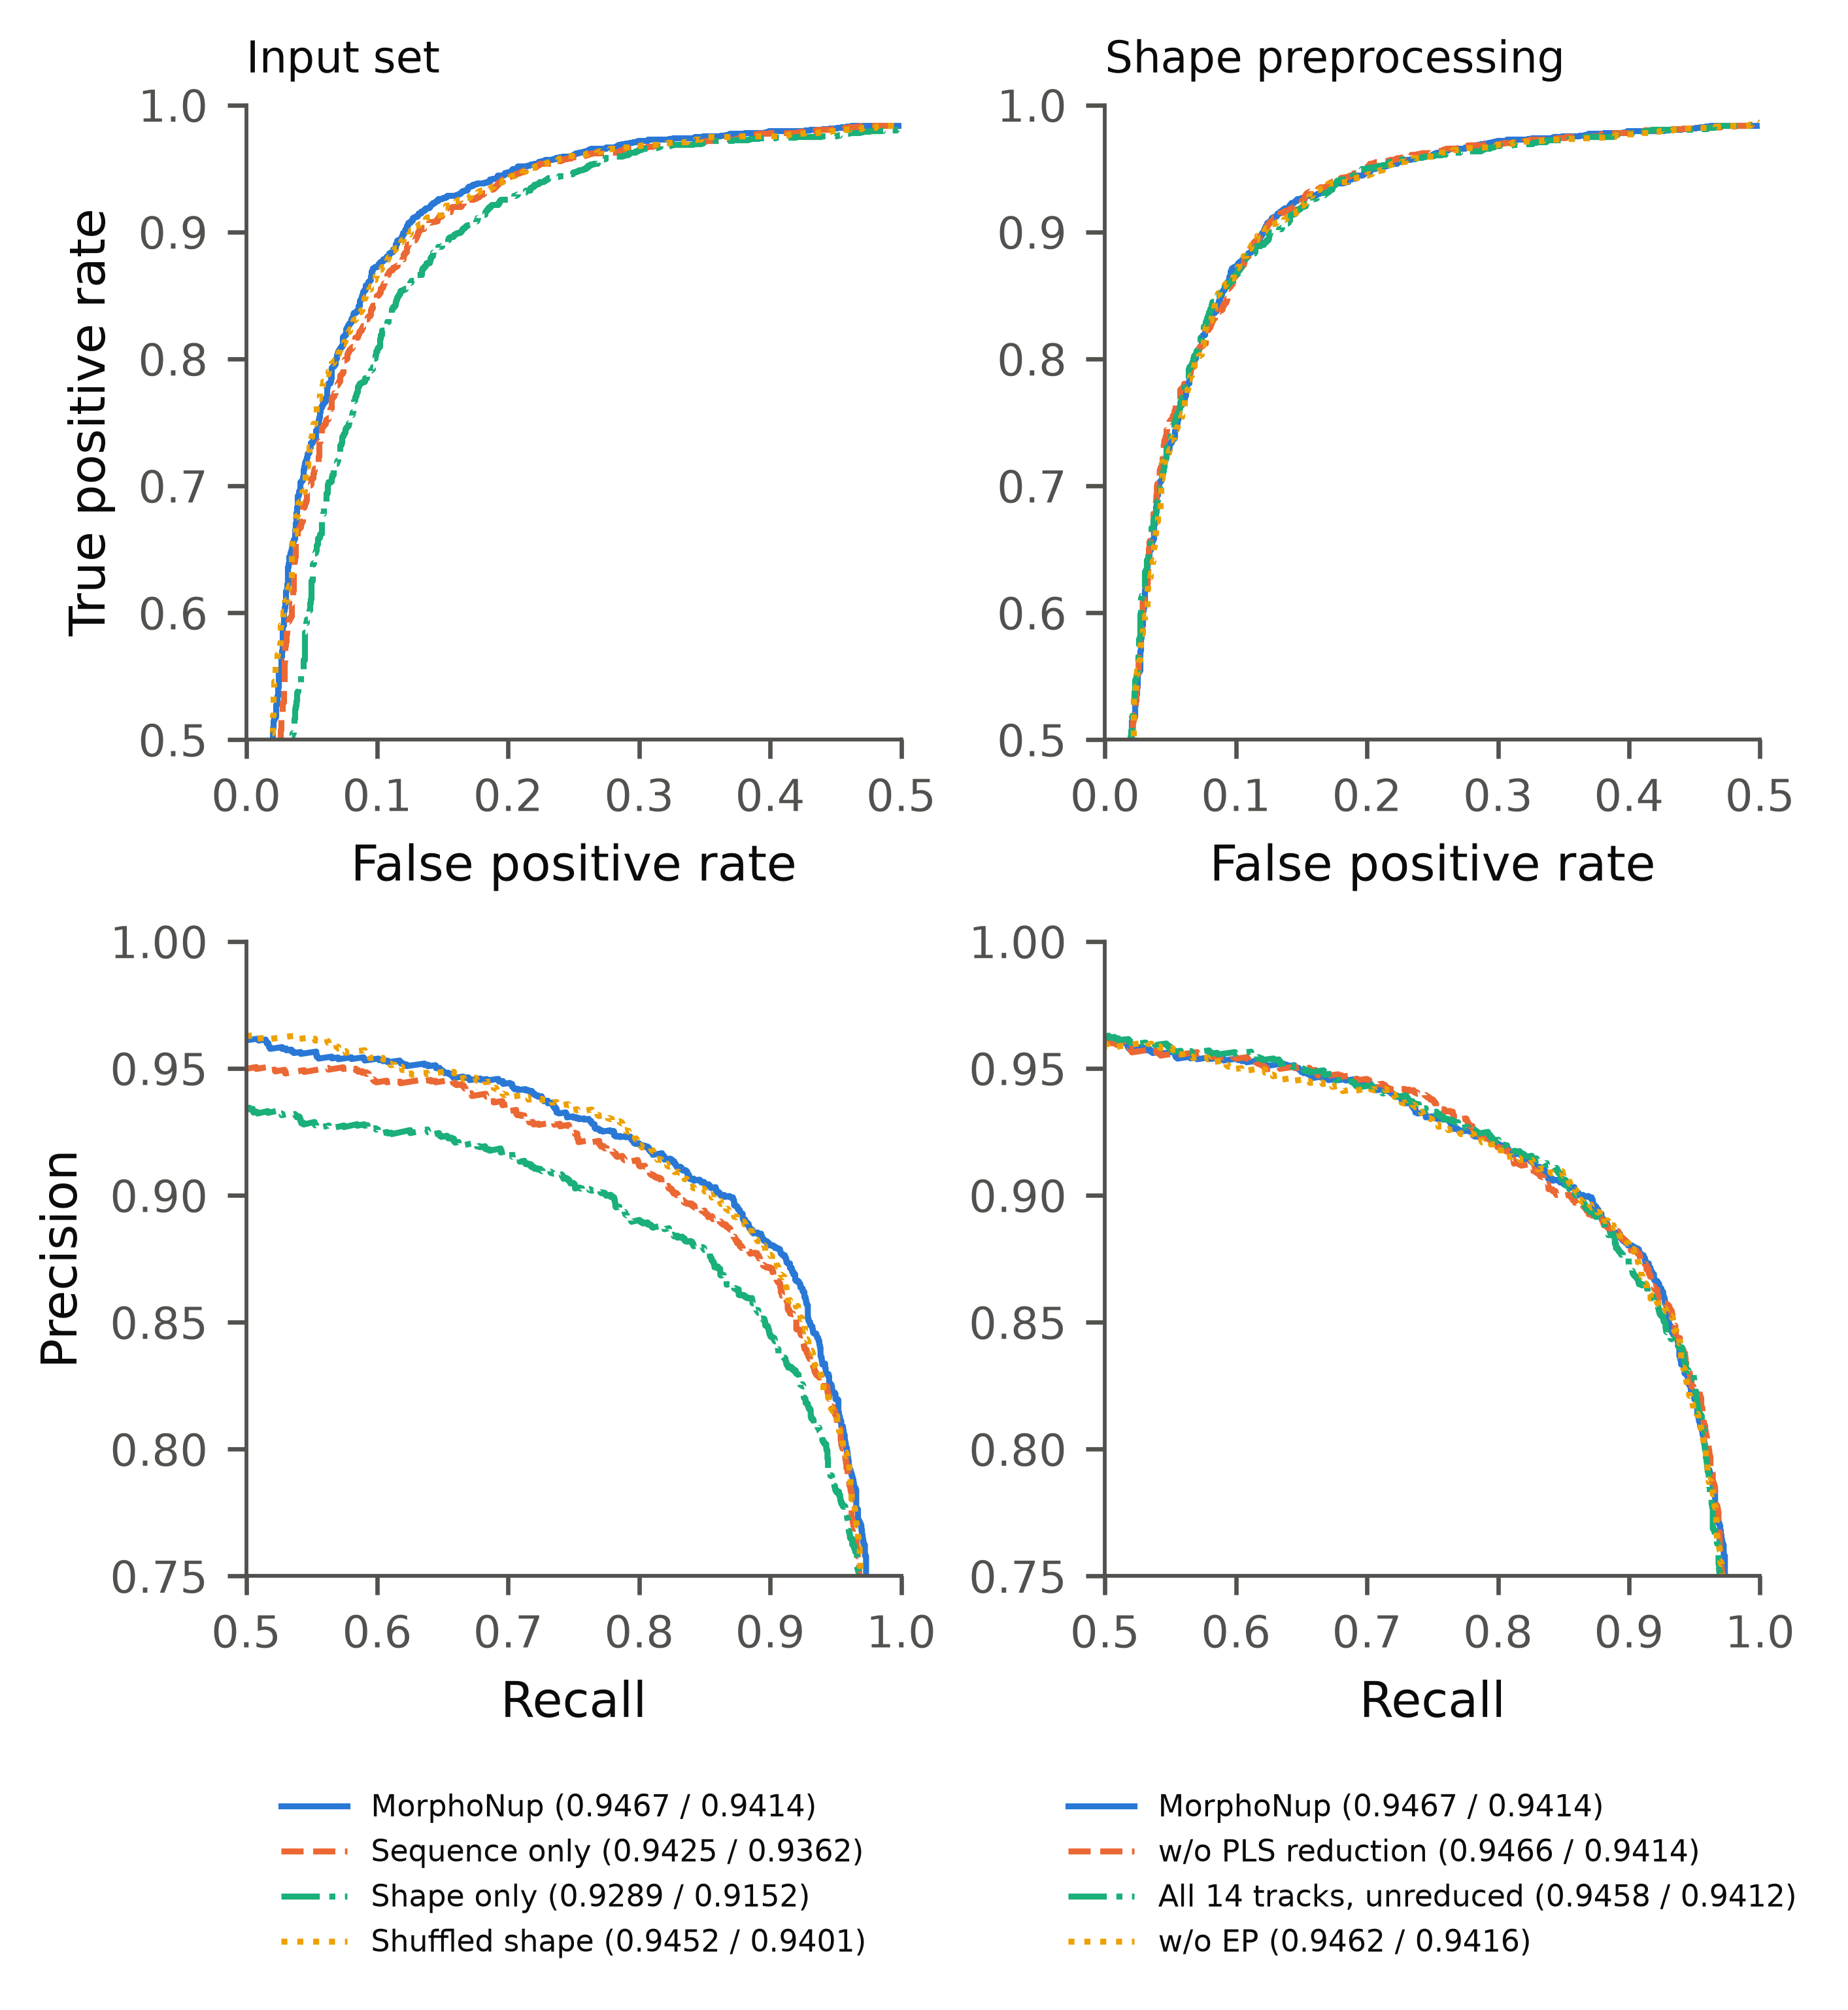

**training_curves** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/modality/figures/training_curves.png`  
Modality analysis: log loss on the tune rows per epoch of the base runs, mean over every outer fold and seed, for MorphoNup and the variants of each part, from epoch 8 (where checkpoint selection starts); a curve stops when fewer than half of its folds are still training (early stopping), so its last epochs average only the longer-running folds.

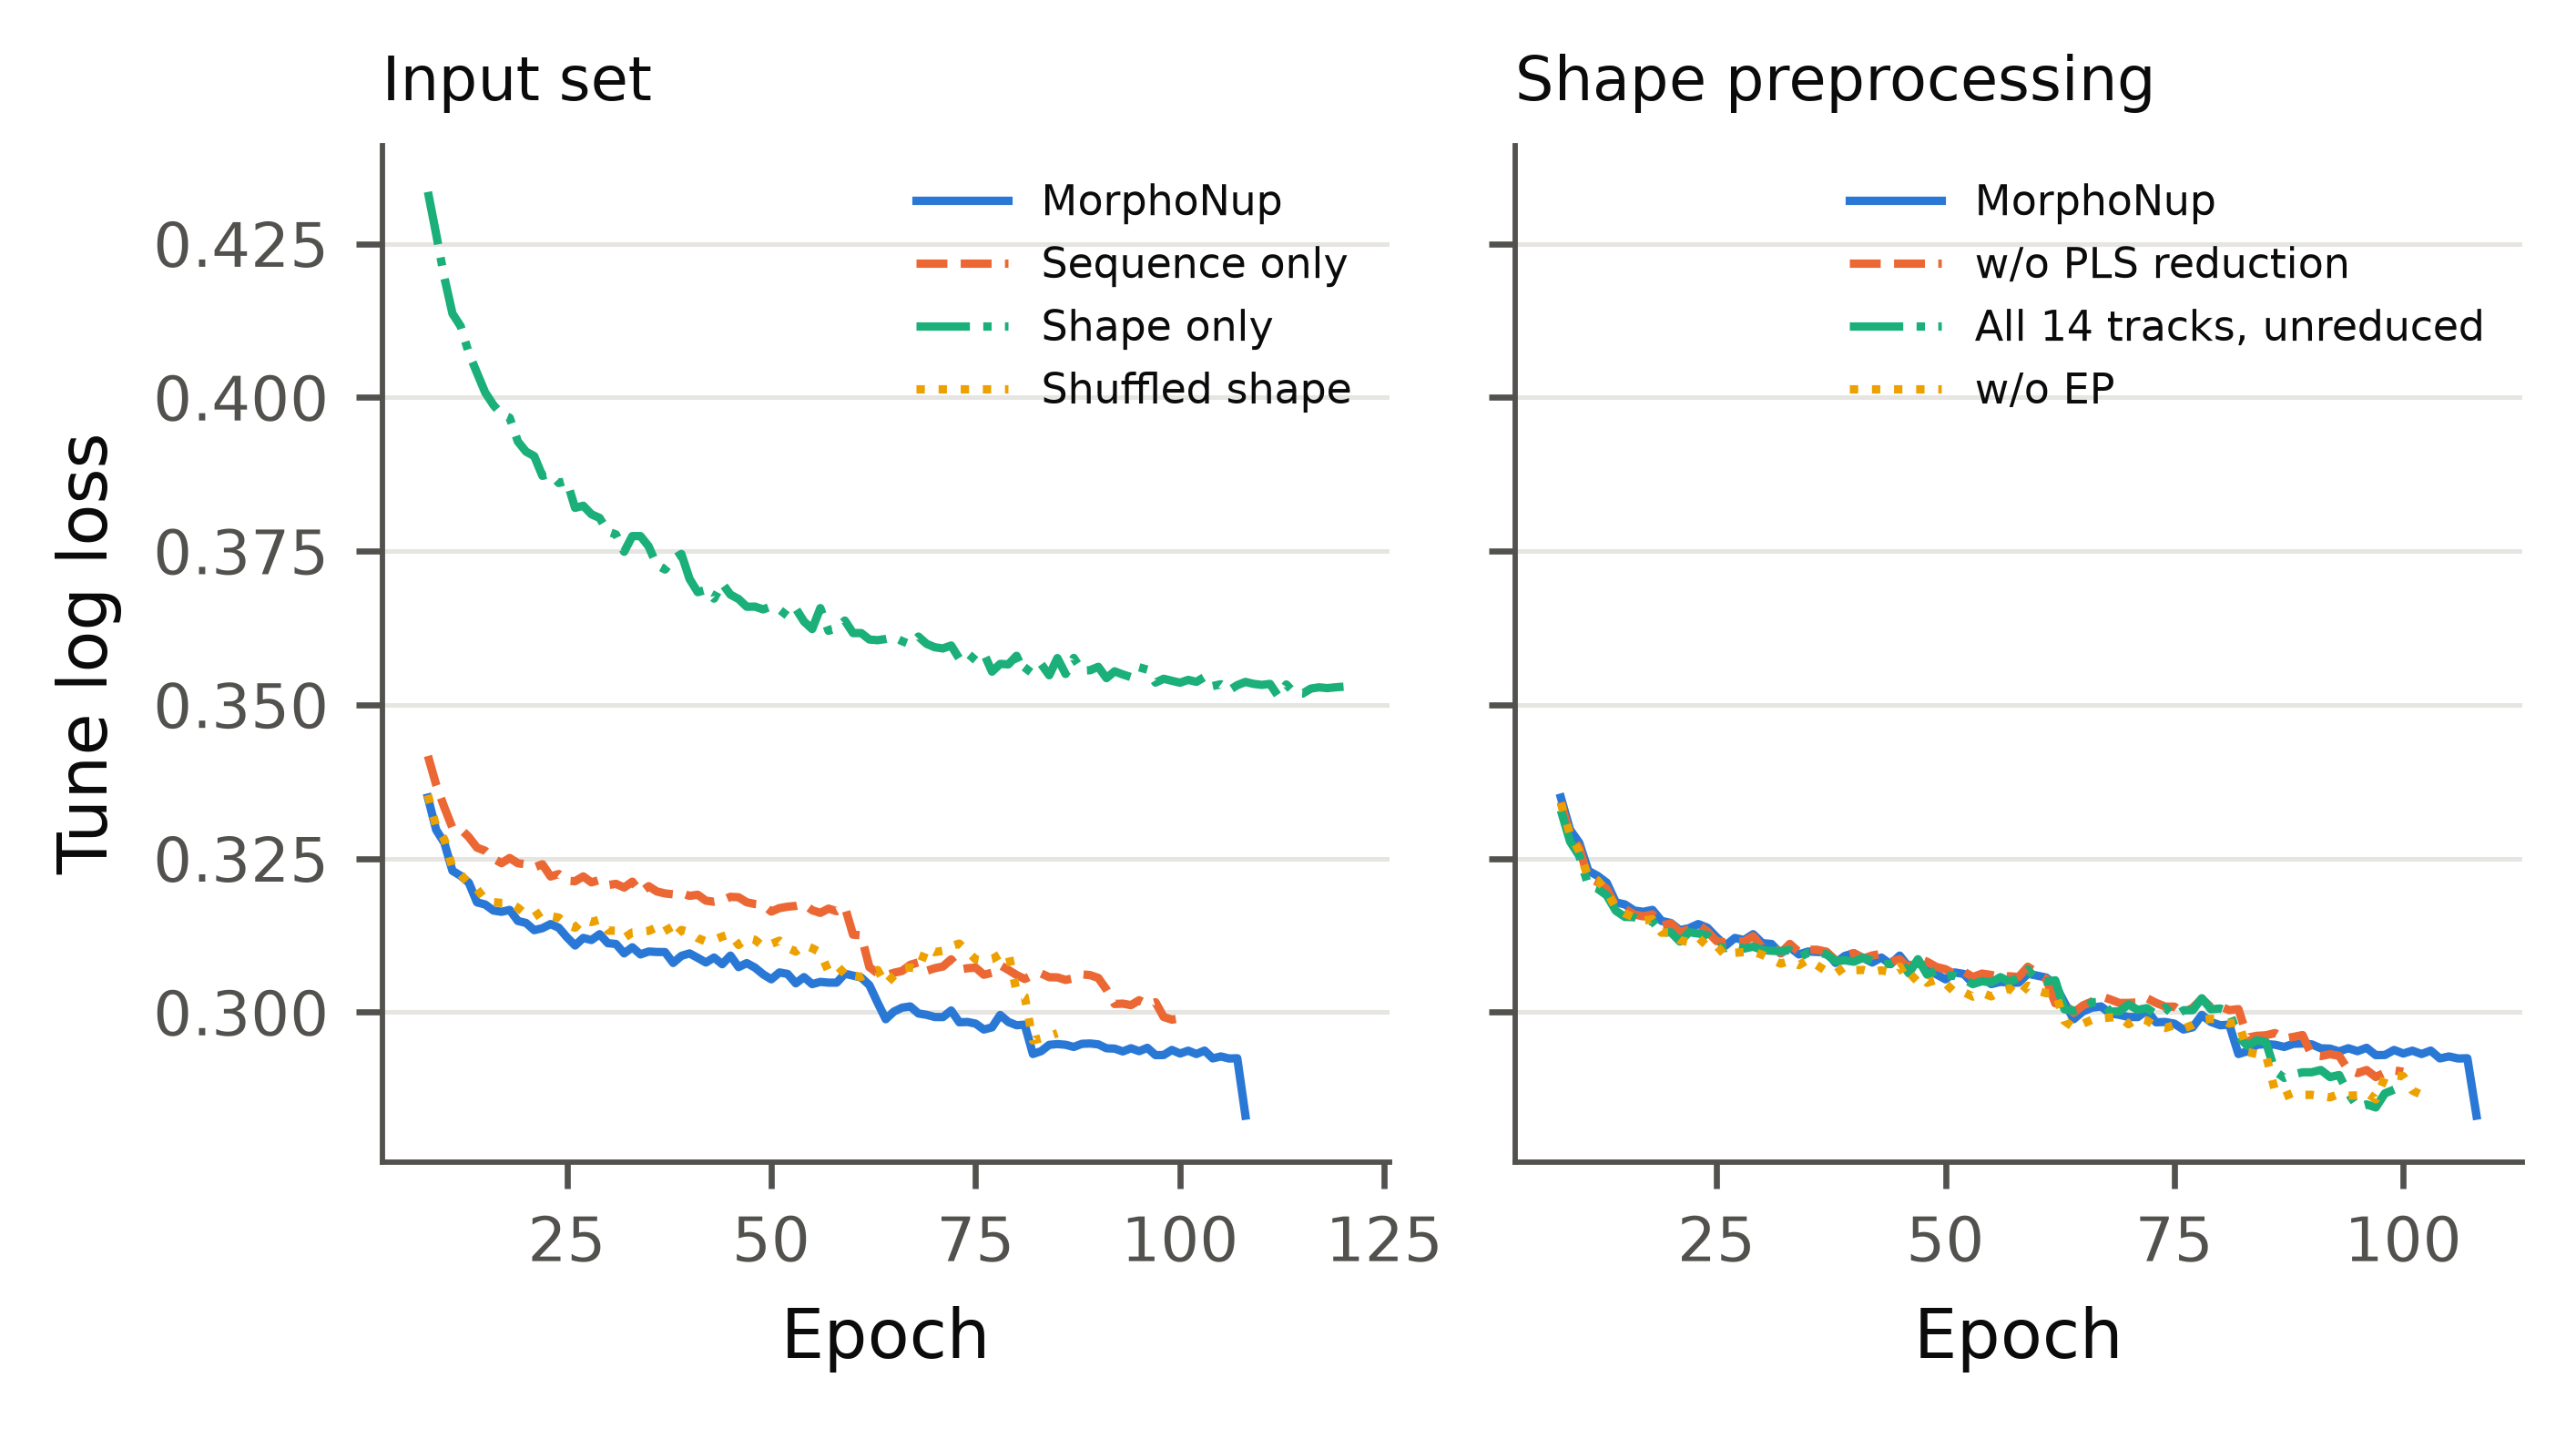

**training_diagnostics** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/modality/figures/training_diagnostics.png`  
Modality analysis: per outer fold and seed, the epoch chosen on the tune rows (left; cap 120) and the gap between training and test accuracy (right) of the reported model. Box: median and quartiles, whiskers 1.5 × IQR; MorphoNup in blue.

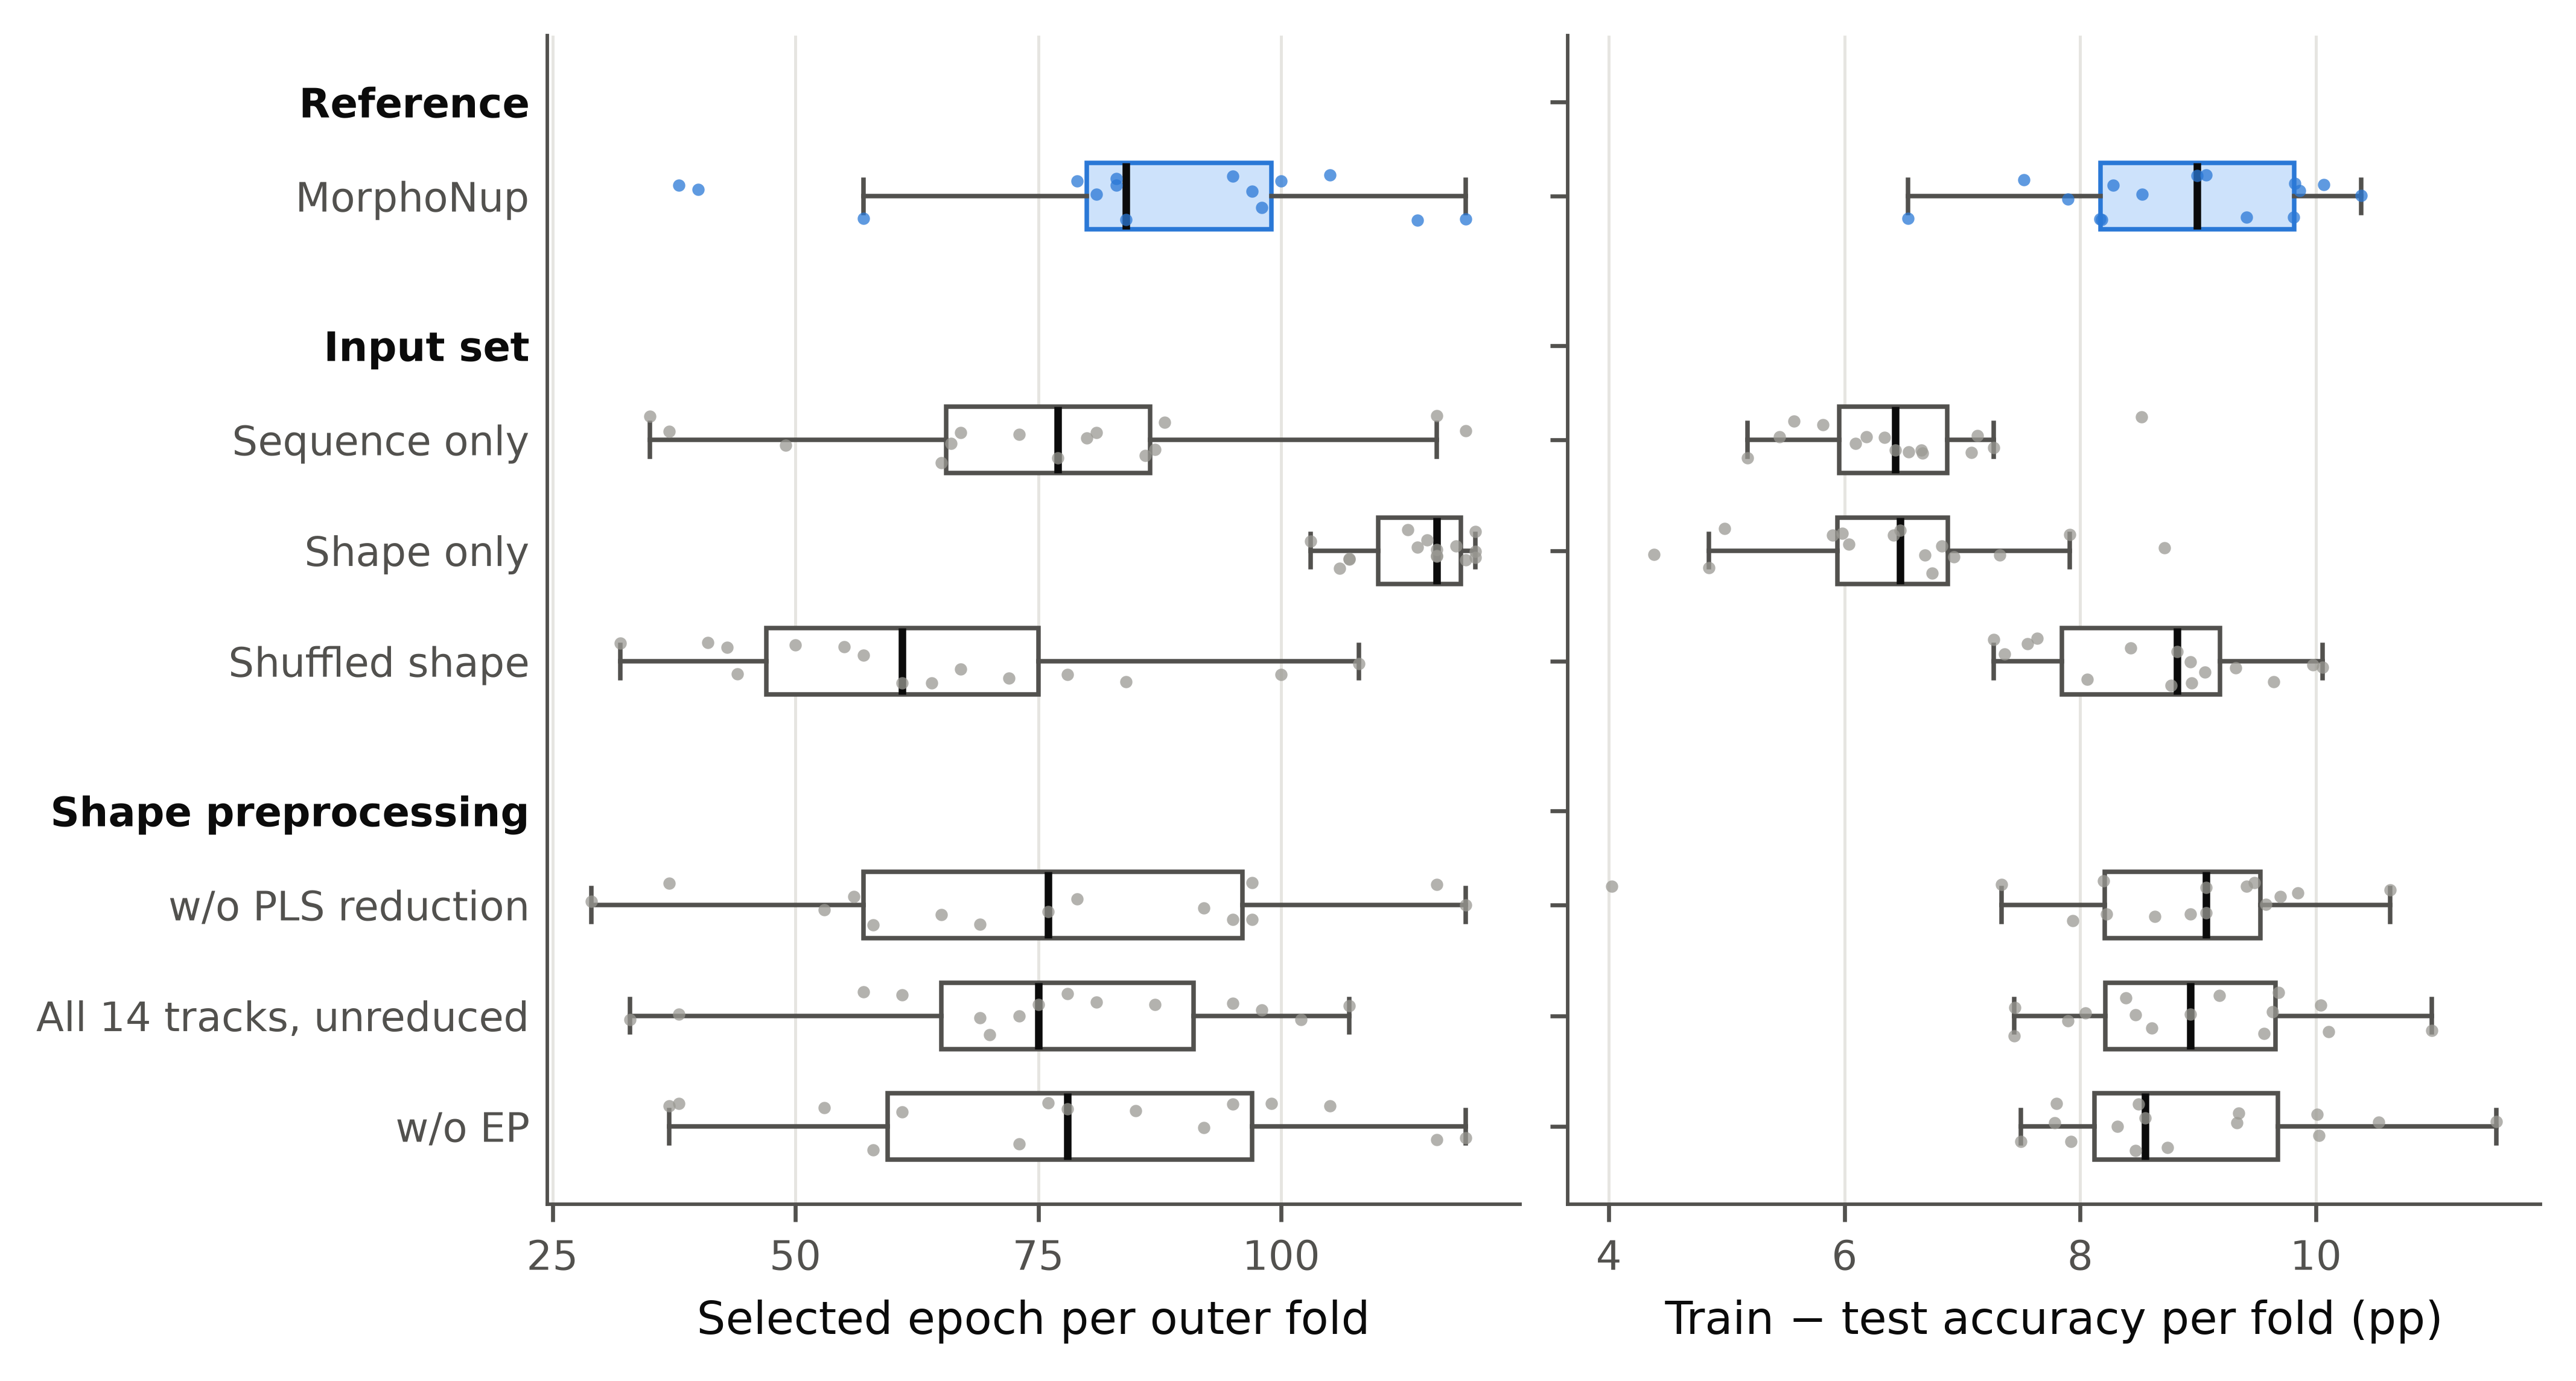

**parameters** — `results/DatasetNup_1/Homo_sapiens/k5/analysis/modality/figures/parameters.png`  
Modality analysis: parameter count of each variant (MorphoNup in blue).

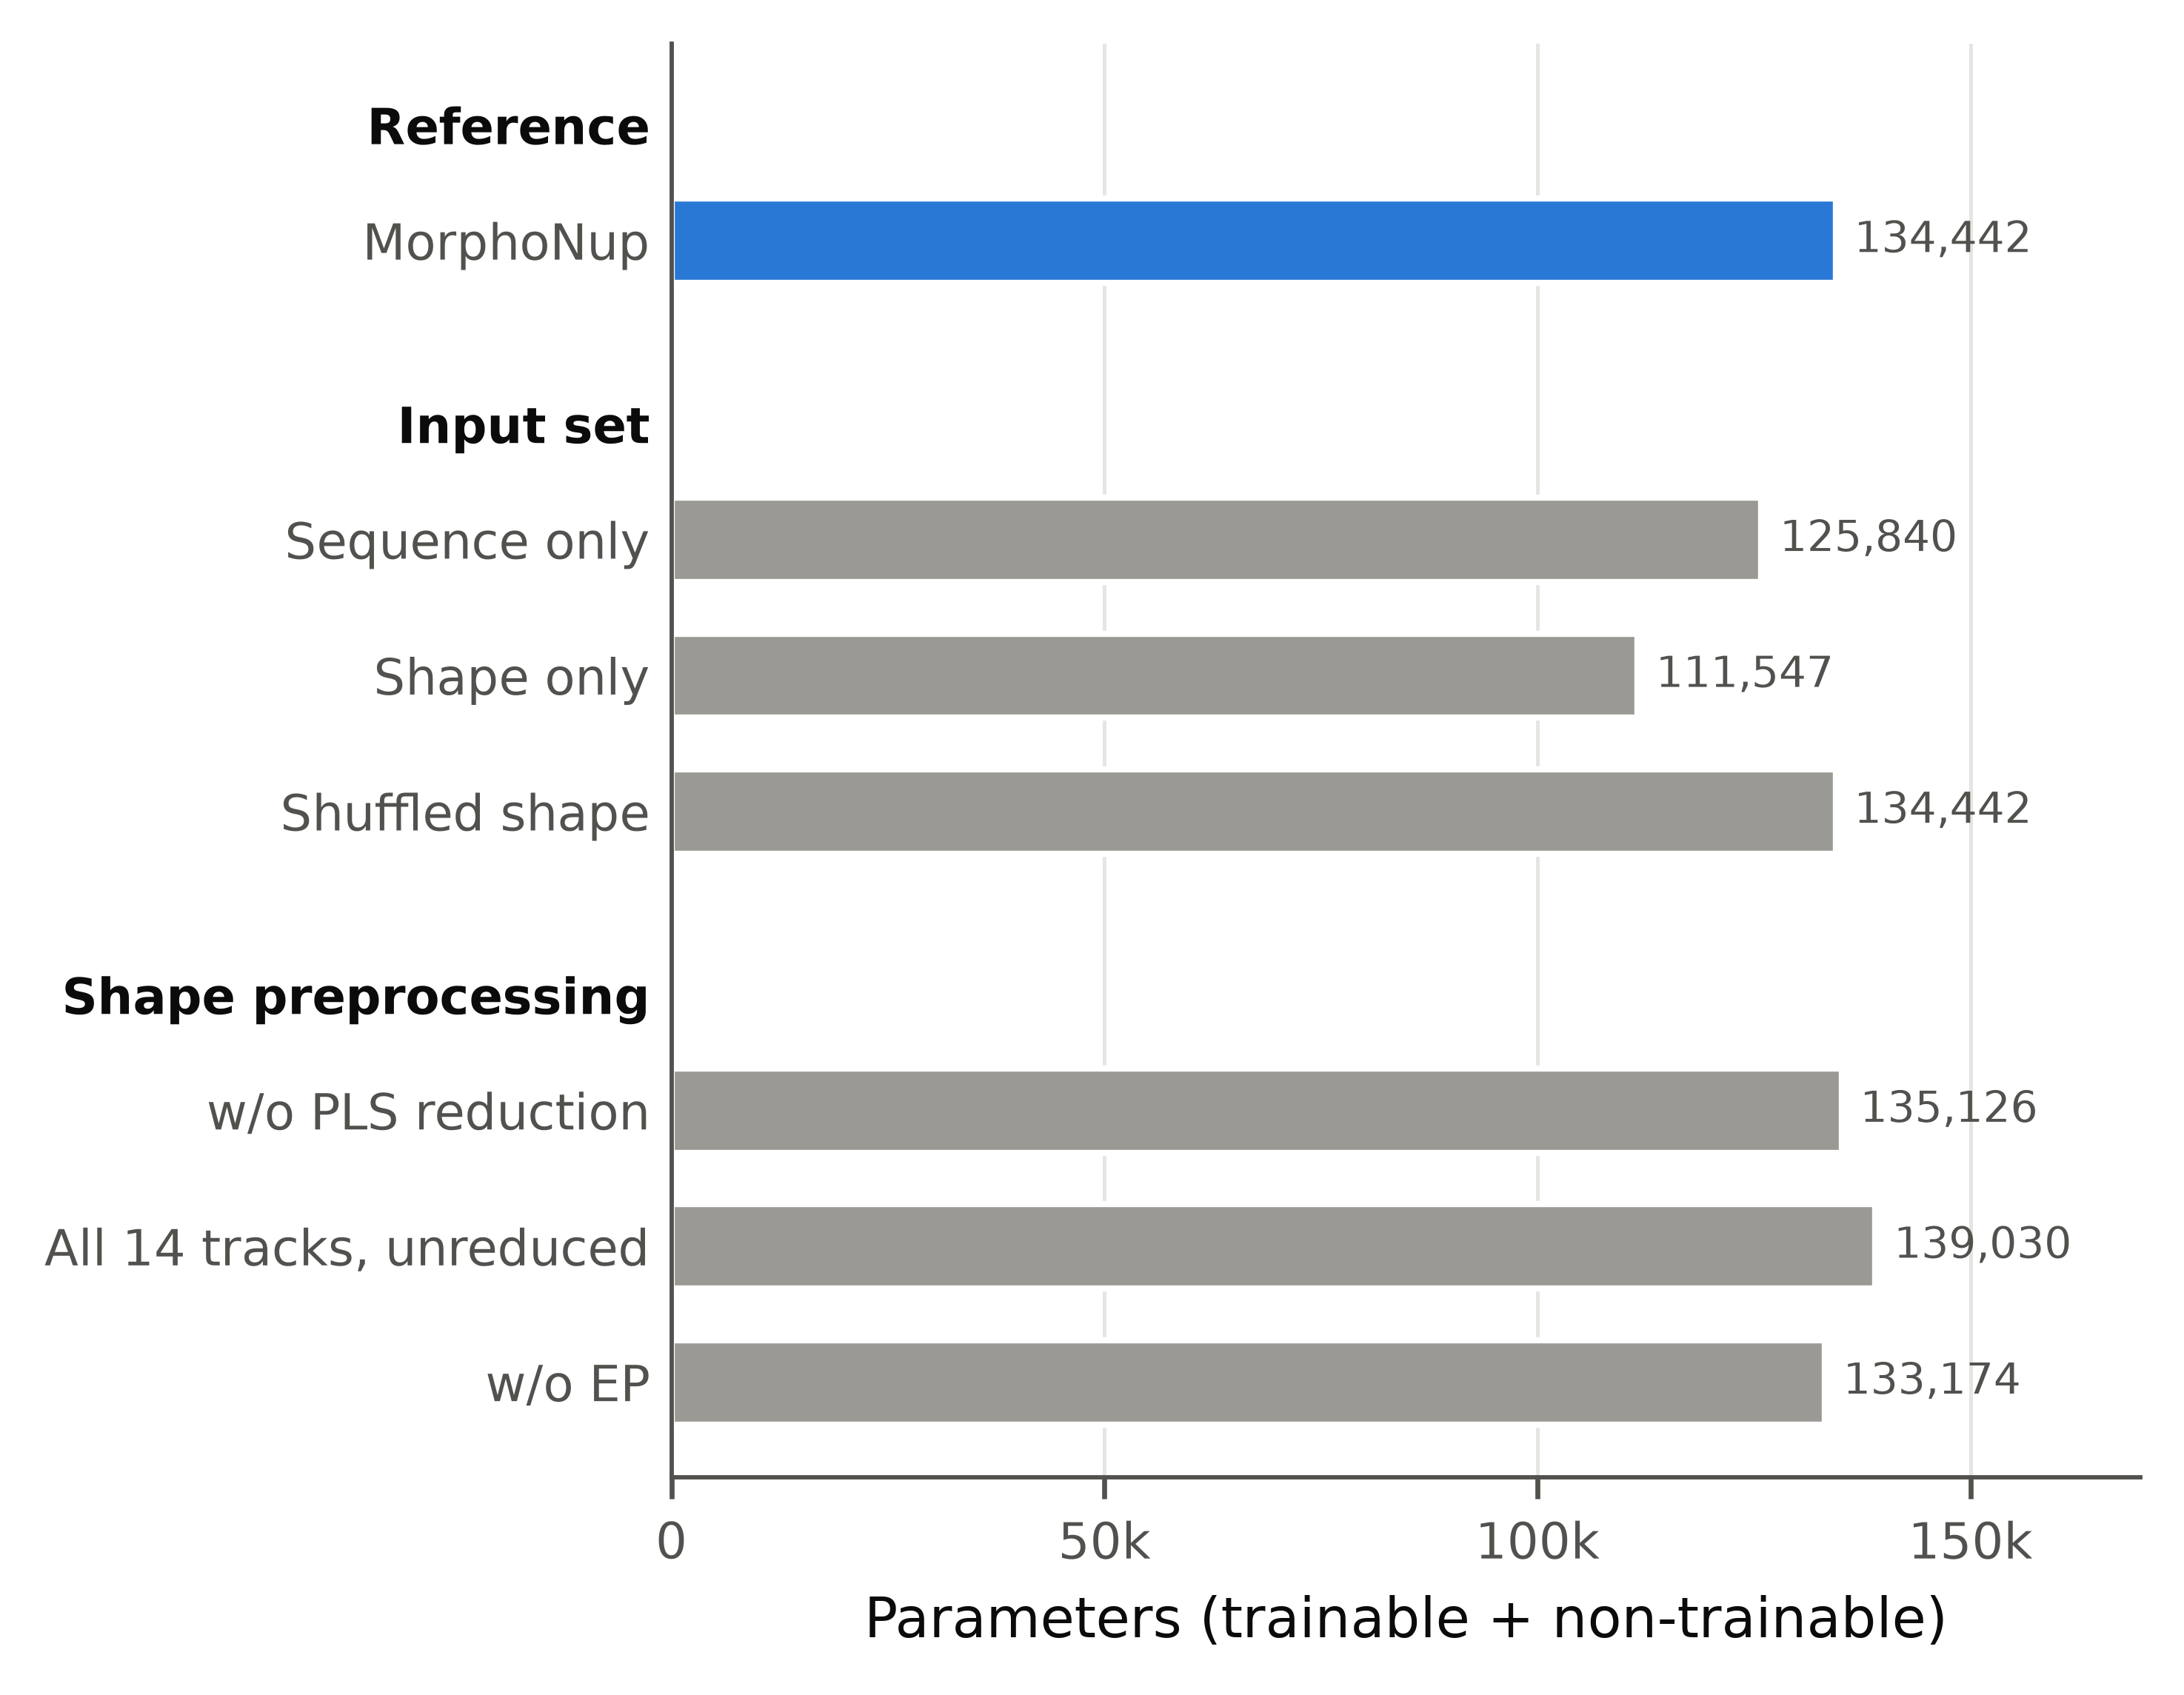

In [7]:
if (OUT / "figures").exists():
    for name in ('deltas', 'boxplot_accuracy', 'roc_pr_arms', 'delta_heatmap', 'metrics_panel', 'accuracy', 'discordance', 'fold_deltas', 'roc_pr_parts', 'training_curves', 'training_diagnostics', 'parameters'):
        if (OUT / "figures" / f"{name}.png").exists():
            show(OUT / "figures" / f"{name}.png")
else:
    print("No figures yet: train at least one arm (RUN_MODE = 'background').")

Per-seed and per-fold numbers: `seed_metrics.csv`, `fold_deltas.csv`, `comparison.csv`, `manuscript_table.csv` in the same folder. Each arm's own run figures are under `results/<dataset>/k<K>/<arm>/`.